# Proyecto de Inteligencia Artificial
## Brecha digital y educación en el Perú 2025
**Estudiante:** Anthony Kelman Mamani Vargas  
**Docente:** Angel Rosendo Condori Coaquira  
**Universidad Peruana Unión — Ingeniería de Sistemas — Ciclo VIII**

Este notebook contiene todo el código del análisis principal dentro de sus celdas. Incluye ingesta, limpieza, integración, EDA, comparación de clústeres, validación agrupada, cuatro clasificadores y SHAP. Las salidas se obtuvieron ejecutando las celdas de principio a fin.

Para repetirlo, instalar las dependencias de `requirements.txt` y ubicar los archivos originales extraídos en `data_cruda`. También puede configurarse `PROYECTO_RAW`. La ejecución entregada utiliza una caché opcional, derivada de los datos crudos, para evitar lecturas repetidas; no es necesaria para ejecutar de nuevo.

La clase positiva significa **no usó internet en el mes anterior**, entre estudiantes de 6 a 17 años que asisten. No representa una prueba de competencias digitales ni un resultado de aprendizaje.

## 1 Entorno y funciones auxiliares
Se fija la semilla 42. Las rutas se resuelven desde la carpeta del proyecto. Las dependencias deben instalarse antes de ejecutar. El límite de hilos reduce el consumo de recursos sin cambiar el diseño de evaluación.

In [1]:
"""Pipeline reproducible de brecha digital ENAHO ESCALE 2025.
Ejecutar desde la raíz: python src/pipeline.py --raw data/raw
Los CSV panel originales pueden estar en subcarpetas.
"""
from pathlib import Path
import os,sys,json,argparse,platform,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit,GroupKFold,GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import *
from sklearn.calibration import calibration_curve
from dbfread import DBF
warnings.filterwarnings('ignore',category=FutureWarning)
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
FIG=ROOT/'evidencias/figuras';TAB=ROOT/'evidencias/tablas';DATA=ROOT/'data_limpia'
for p in [FIG,TAB,DATA]:p.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.prop_cycle':plt.cycler(color=['#023052','#1F6581','#D69A35','#A34B56'])})
SEED=42

from IPython.display import display, Image
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
RAW=Path(os.environ.get('PROYECTO_RAW',str(ROOT/'data_cruda')))
CACHE=Path(os.environ['PROYECTO_CACHE']) if os.environ.get('PROYECTO_CACHE') else None
print('Python:',platform.python_version())
print('Semilla:',SEED)
print('Datos crudos:',RAW)
print('Cache opcional de columnas 2025:',CACHE)

def save(name):
 plt.tight_layout();plt.savefig(FIG/f'{name}.png',dpi=220,bbox_inches='tight');plt.close()

def table(d,name):d.to_csv(TAB/f'{name}.csv',index=False,encoding='utf-8-sig')

def num(s):return pd.to_numeric(s,errors='coerce')

Python: 3.12.14
Semilla: 42
Datos crudos: C:\Users\glady\Documents\Codex\2026-10-27\hola-vamos-a-trabajar-este-trabajo-19\work\raw
Cache opcional de columnas 2025: C:\Users\glady\Documents\Codex\2026-10-27\hola-vamos-a-trabajar-este-trabajo-19\work\selected


## 2 Ingesta de los datos originales
Los archivos INEI son paneles anchos 2021–2025 en UTF-8 con BOM. Se seleccionan las columnas de 2025 y se conservan las claves como texto. La función permite leer una caché opcional de esas mismas columnas. ESCALE se lee desde el padrón DBF.

In [2]:
def load(raw,cache=None):
 specs={'100':['P1121','P1144','P1142','P104','P105A','P110','P111A','ALTITUD','FACTOR07'], '200':['P208A','P207','P204','P205','P206','FACPOB07'], '300':['P300A','P306','P307','P308A','P308B','P308C','P314A','P314D','P316_5'], 'sumaria':['MIEPERHO','GASHOG2D','INGHOG2D','POBREZA','FACTOR07']}
 keys=['AÑO','MES','CONGLOME','VIVIENDA','HOGAR','UBIGEO','ESTRATO','DOMINIO']
 dfs={}; inv=[]
 for name,vars in specs.items():
  required=keys+vars+(['CODPERSO'] if name in ['200','300'] else [])
  if cache and (cache/f'{name}.pkl').exists():
   d=pd.read_pickle(cache/f'{name}.pkl');d=d[[c for c in required if c in d]]
  else:
   pattern='sumaria-2021-2025-panel.csv' if name=='sumaria' else f'*-{name}-panel.csv'
   f=next(raw.rglob(pattern));header=pd.read_csv(f,encoding='utf-8-sig',nrows=0)
   cols=[c for c in header if c.endswith('_25') and c[:-3].upper() in required]
   d=pd.read_csv(f,usecols=cols,encoding='utf-8-sig',dtype=str)
   d.columns=[c[:-3].upper() for c in d];d=d.apply(lambda x:x.str.strip().replace('',np.nan));d=d[d['AÑO'].eq('2025')]
  dfs[name]=d;inv.append({'fuente':name,'registros_2025':len(d),'variables_seleccionadas':len(d.columns)})
  print('INGESTA',name,d.shape,flush=True)
 table(pd.DataFrame(inv),'inventario_2025')
 if cache and (cache/'padron.pkl').exists():pad=pd.read_pickle(cache/'padron.pkl')
 else:pad=pd.DataFrame(iter(DBF(str(next(raw.rglob('Padron.dbf'))),encoding='latin1',char_decode_errors='ignore')))
 return dfs,pad

In [3]:
dfs,pad=load(RAW,CACHE)
display(pd.read_csv(TAB/'inventario_2025.csv'))

INGESTA 100 (44599, 17)
INGESTA 200 (115145, 15)
INGESTA 300 (106958, 18)
INGESTA sumaria (33702, 13)


,fuente,registros_2025,variables_seleccionadas
0,100,44599,17
1,200,115145,15
2,300,106958,18
3,sumaria,33702,13


## 3 Limpieza e integración
Se validan claves y cardinalidades. Las personas se cruzan por conglomerado, vivienda, hogar y persona; los módulos de hogar, por su clave compuesta. El padrón se agrega por distrito y área antes de unirse. Se filtran residentes habituales de 6 a 17 años y asistentes con respuesta válida sobre internet. No se imputa la etiqueta.

In [4]:
def prepare(dfs,pad):
 h=['CONGLOME','VIVIENDA','HOGAR'];person=h+['CODPERSO'];audit=[]
 def unique(d,keys,name):
  null=d[keys].isna().any(axis=1); dup=d.loc[~null].duplicated(keys).sum()
  audit.append({'etapa':name,'entrada':len(d),'llave_nula':int(null.sum()),'duplicados':int(dup)})
  if dup:raise ValueError(f'Llaves duplicadas en {name}: {dup}')
  return d.loc[~null].copy()
 m=unique(dfs['200'],person,'200');age=num(m.P208A);m=m.loc[age.between(6,17)].copy()
 # Residentes habituales: miembros no ausentes o no miembros presentes >=30 días.
 res=(m.P204.eq('1')&m.P205.eq('2'))|(m.P204.eq('2')&m.P206.eq('1'))
 audit.append({'etapa':'edad 6 a 17 y residencia','entrada':len(m),'salida':int(res.sum())});m=m[res]
 edu=unique(dfs['300'],person,'300')
 edu=edu[person+[c for c in edu if c not in m and c not in person]]
 m=m.merge(edu,on=person,how='left',validate='one_to_one',indicator='_edu')
 joins=[{'union':'200 + 300','coinciden':int(m._edu.eq('both').sum()),'no_coinciden':int(m._edu.ne('both').sum())}]
 for name,cols in [('100',['P1121','P1144','P1142','P104','ALTITUD']),('sumaria',['MIEPERHO','GASHOG2D','INGHOG2D','POBREZA'])]:
  d=unique(dfs[name],h,name);cols=[c for c in cols if c in d]
  m=m.merge(d[h+cols],on=h,how='left',validate='many_to_one',indicator='_m')
  joins.append({'union':name,'coinciden':int(m._m.eq('both').sum()),'no_coinciden':int(m._m.ne('both').sum())});m=m.drop(columns='_m')
 table(pd.DataFrame(audit),'auditoria_llaves');table(pd.DataFrame(joins),'auditoria_uniones')
 table(pd.DataFrame({'variable':m.columns,'faltantes_crudos':m.isna().sum().values,'porcentaje':100*m.isna().mean().values}),'calidad_cruda')
 # Padrón: servicios activos de primaria y secundaria EBR, nivel B0 y F0.
 pad=pad[pad.ESTADO.eq('1')&pad.NIV_MOD.isin(['B0','F0'])].copy()
 assert not pad.duplicated(['COD_MOD','ANEXO']).any()
 pad['rural']=pad.AREA_CENSO.eq('2').astype(int);pad['publico']=pad.GESTION.isin(['1','2']).astype(int)
 for c in ['TALUM','TDOC']:pad[c]=num(pad[c]);pad.loc[pad[c]<0,c]=np.nan
 pad['lat']=num(pad.NLAT_IE);pad['lon']=num(pad.NLONG_IE)
 pad.loc[~pad.lat.between(-19,0),'lat']=np.nan;pad.loc[~pad.lon.between(-82,-68),'lon']=np.nan
 agg=pad.groupby(['CODGEO','rural']).agg(servicios=('COD_MOD','size'),alumnos=('TALUM',lambda x:x.sum(min_count=1)),docentes=('TDOC',lambda x:x.sum(min_count=1)),proporcion_publica=('publico','mean'),latitud=('lat','mean'),longitud=('lon','mean')).reset_index()
 agg['ratio_alumno_docente']=agg.alumnos/agg.docentes.replace(0,np.nan)
 table(agg,'contexto_distrital_escale')
 m['rural']=(num(m.ESTRATO)>=6).astype(int)
 m=m.merge(agg,left_on=['UBIGEO','rural'],right_on=['CODGEO','rural'],how='left',validate='many_to_one',indicator='_escale')
 joins.append({'union':'ESCALE distrito y area','coinciden':int(m._escale.eq('both').sum()),'no_coinciden':int(m._escale.ne('both').sum())});table(pd.DataFrame(joins),'auditoria_uniones')
 for c in ['P314A','P307','P306']:
  if c in m:m.loc[~m[c].isin(['1','2']),c]=np.nan
 m['edad']=num(m.P208A);m['sexo']=m.P207;m['lengua']=m.P300A
 m['internet_hogar']=m.P1144.map({'1':1,'0':0});m['electricidad']=m.P1121.map({'1':1,'0':0})
 m['miembros']=num(m.MIEPERHO);m['gasto_mensual_pc']=num(m.GASHOG2D)/(12*m.miembros.replace(0,np.nan))
 m.loc[m.gasto_mensual_pc<0,'gasto_mensual_pc']=np.nan
 m['log_gasto_pc']=np.log1p(m.gasto_mensual_pc);m['peso']=num(m.FACPOB07)
 m['altitud']=num(m['ALTITUD']) if 'ALTITUD' in m else np.nan
 m['sin_uso_internet']=m.P314A.map({'1':0,'2':1})
 n_age=len(m);m=m.loc[m.P307.eq('1')&m.sin_uso_internet.notna()].copy().reset_index(drop=True)
 flow=pd.DataFrame([{'etapa':'Residentes de 6 a 17 años con cruces','n':n_age},{'etapa':'Asisten y tienen respuesta valida P314A','n':len(m)},{'etapa':'Excluidos por asistencia o respuesta','n':n_age-len(m)}]);table(flow,'flujo_poblacion')
 table(m[['edad','rural','internet_hogar','electricidad','gasto_mensual_pc','ratio_alumno_docente','sin_uso_internet']].describe().T.reset_index(),'descriptivos')
 # Guardar base local con claves necesarias para reproducir particiones; gitignore la excluye.
 m.to_csv(DATA/'dataset_enaho_escale_2025.csv',index=False,encoding='utf-8-sig')
 return m

In [5]:
m=prepare(dfs,pad)
for archivo in ['auditoria_llaves','auditoria_uniones','flujo_poblacion','calidad_cruda']:
 print(archivo);display(pd.read_csv(TAB/f'{archivo}.csv'))
print('Población analítica:',len(m))

auditoria_llaves
auditoria_uniones
flujo_poblacion
calidad_cruda
Población analítica: 17807


,etapa,entrada,llave_nula,duplicados,salida
0,200,115145,0.0,0.0,NaN
1,edad 6 a 17 y residencia,24195,NaN,NaN,23345.0
2,300,106958,0.0,0.0,NaN
3,100,44599,0.0,0.0,NaN
4,sumaria,33702,0.0,0.0,NaN


,union,coinciden,no_coinciden
0,200 + 300,23345,0
1,100,23345,0
2,sumaria,23345,0
3,ESCALE distrito y area,22920,425


,etapa,n
0,Residentes de 6 a 17 años con cruces,23345
1,Asisten y tienen respuesta valida P314A,17807
2,Excluidos por asistencia o respuesta,5538


,variable,faltantes_crudos,porcentaje
0,AÑO,0,0.000000
1,MES,0,0.000000
2,CONGLOME,0,0.000000
3,VIVIENDA,0,0.000000
4,HOGAR,0,0.000000
5,UBIGEO,0,0.000000
6,ESTRATO,0,0.000000
7,DOMINIO,0,0.000000
8,P208A,0,0.000000
9,P207,0,0.000000


## 4 EDA
Se comparan estimaciones muestrales y ponderadas con FACPOB07. Las figuras describen distribuciones, faltantes y relaciones; no establecen causalidad. Las tasas corresponden a la población seleccionada.

In [6]:
def eda(m):
 rows=[]
 for r,g in m.groupby('rural'):
  valid=g.peso.notna()&g.peso.gt(0)
  rows.append({'area':'Rural' if r else 'Urbana','n':len(g),'sin_uso_muestral':g.sin_uso_internet.mean(),'sin_uso_ponderado':np.average(g.loc[valid,'sin_uso_internet'],weights=g.loc[valid,'peso']),'internet_hogar':g.internet_hogar.mean()})
 d=pd.DataFrame(rows);table(d,'brecha_por_area');d.set_index('area')[['sin_uso_muestral','sin_uso_ponderado','internet_hogar']].mul(100).plot.bar(figsize=(8,4));plt.ylabel('Porcentaje');plt.xticks(rotation=0);plt.legend(['Sin uso muestra','Sin uso ponderado','Internet hogar'],fontsize=8);save('01_brecha_area')
 fig,ax=plt.subplots(1,2,figsize=(9,3.5));m.edad.hist(ax=ax[0],bins=np.arange(5.5,18.5));ax[0].set_title('Edad de estudiantes');ax[0].set_xlabel('Años');m.gasto_mensual_pc.plot.hist(ax=ax[1],bins=40);ax[1].set_title('Gasto mensual por persona');ax[1].set_xlabel('Soles');save('02_distribuciones')
 missing=m[['internet_hogar','electricidad','log_gasto_pc','ratio_alumno_docente','altitud','lengua']].isna().mean()*100
 missing.plot.barh(figsize=(7,3.5));plt.xlabel('Porcentaje faltante antes de imputar');save('03_faltantes')
 features=['internet_hogar','electricidad','log_gasto_pc','miembros','ratio_alumno_docente','rural']
 corr=m[features+['sin_uso_internet']].corr();table(corr.reset_index(),'correlaciones')
 plt.figure(figsize=(8,5));plt.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r');plt.colorbar(label='Correlación Pearson');plt.xticks(range(len(corr)),corr.columns,rotation=60,ha='right',fontsize=8);plt.yticks(range(len(corr)),corr.index,fontsize=8);save('04_correlaciones')
 return d

,area,n,sin_uso_muestral,sin_uso_ponderado,internet_hogar
0,Urbana,11421,0.176867,0.180456,0.979249
1,Rural,6386,0.399937,0.392922,0.921704


,index,count,mean,std,min,25%,50%,75%,max
0,edad,17807.0,11.577189,3.289229,6.000000,9.000000,12.000000,14.000000,17.000000
1,rural,17807.0,0.358623,0.479610,0.000000,0.000000,0.000000,1.000000,1.000000
2,internet_hogar,17807.0,0.958612,0.199192,0.000000,1.000000,1.000000,1.000000,1.000000
3,electricidad,17807.0,0.927276,0.259691,0.000000,1.000000,1.000000,1.000000,1.000000
4,gasto_mensual_pc,17807.0,663.216880,457.394266,57.175838,376.055794,549.567057,803.584467,6634.001953
5,ratio_alumno_docente,17440.0,14.951403,4.436838,2.000000,11.718310,15.934411,18.269391,30.268293
6,sin_uso_internet,17807.0,0.256865,0.436917,0.000000,0.000000,0.000000,1.000000,1.000000


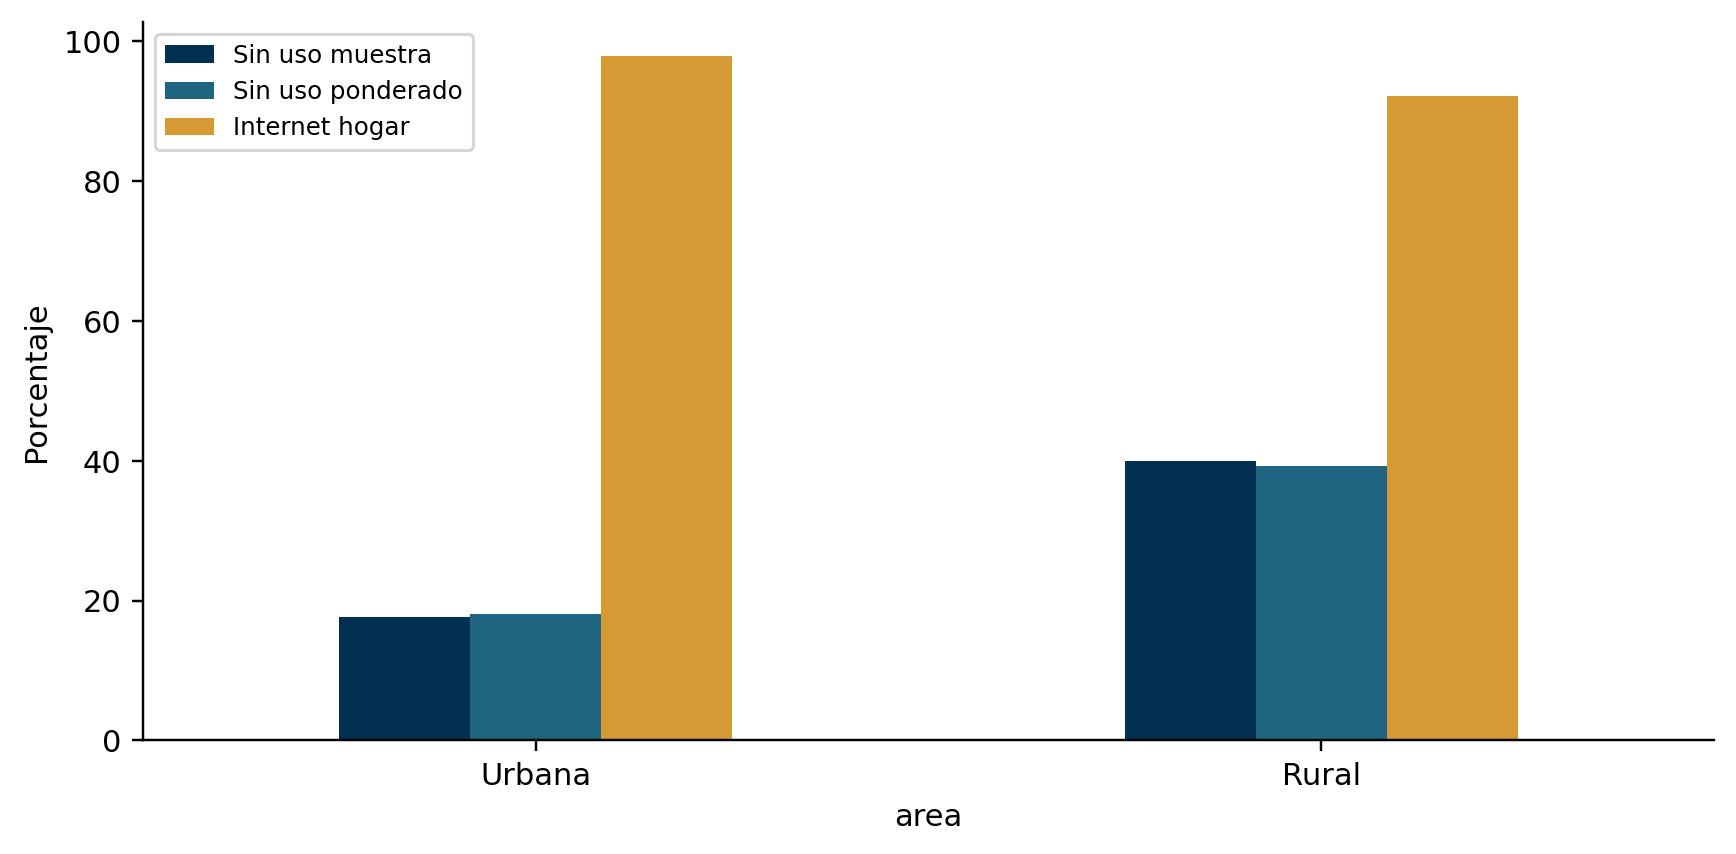

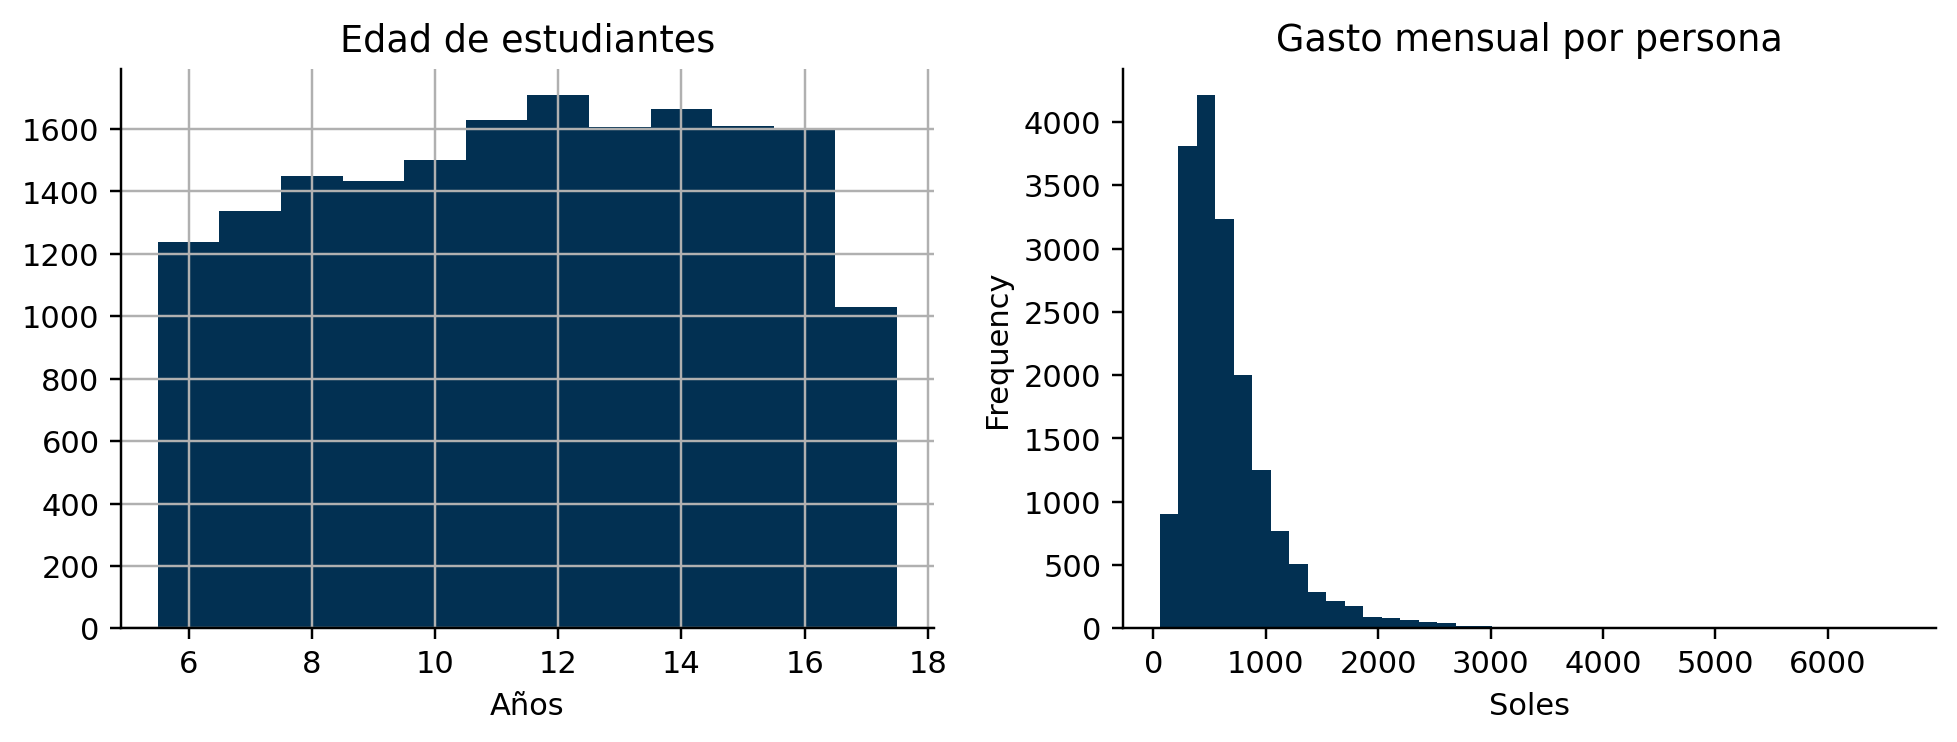

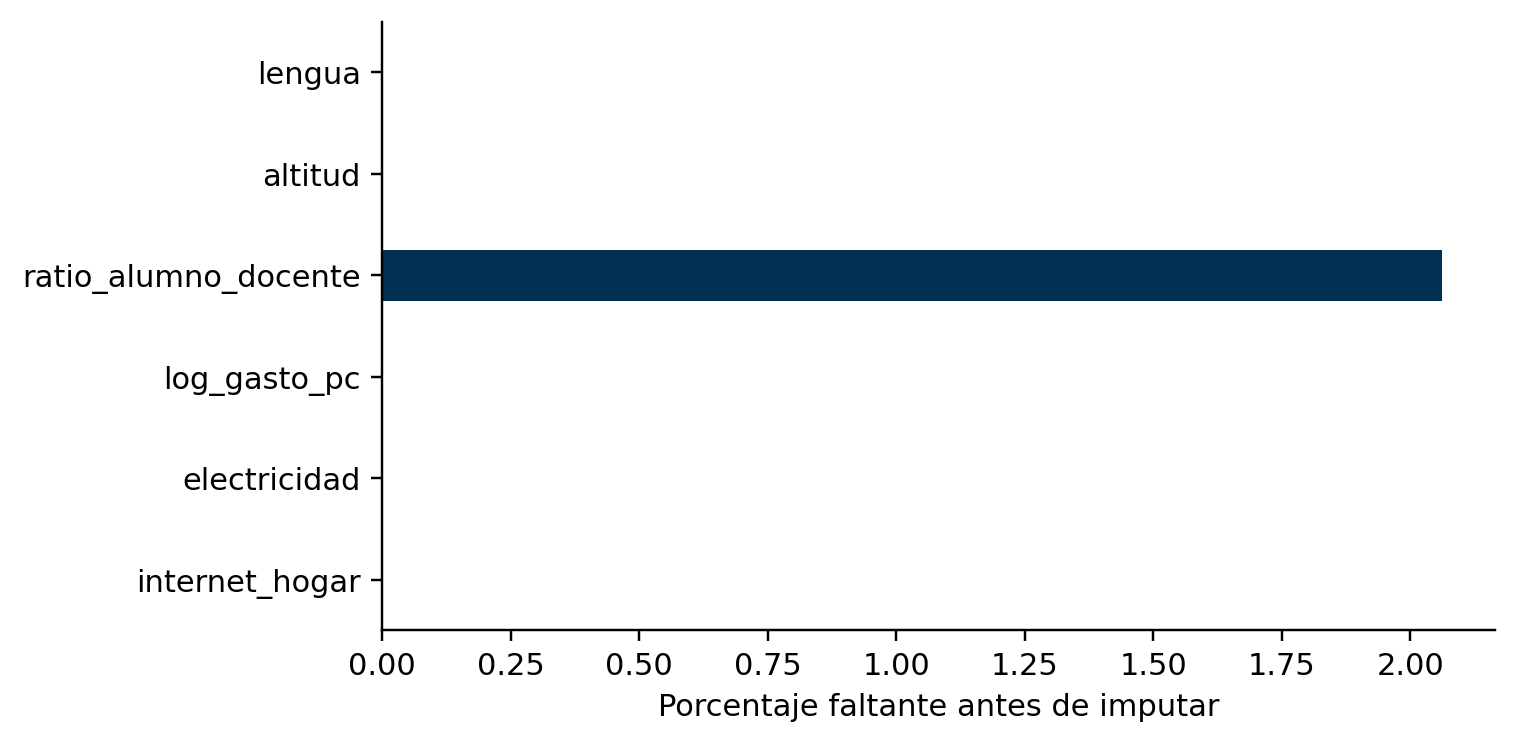

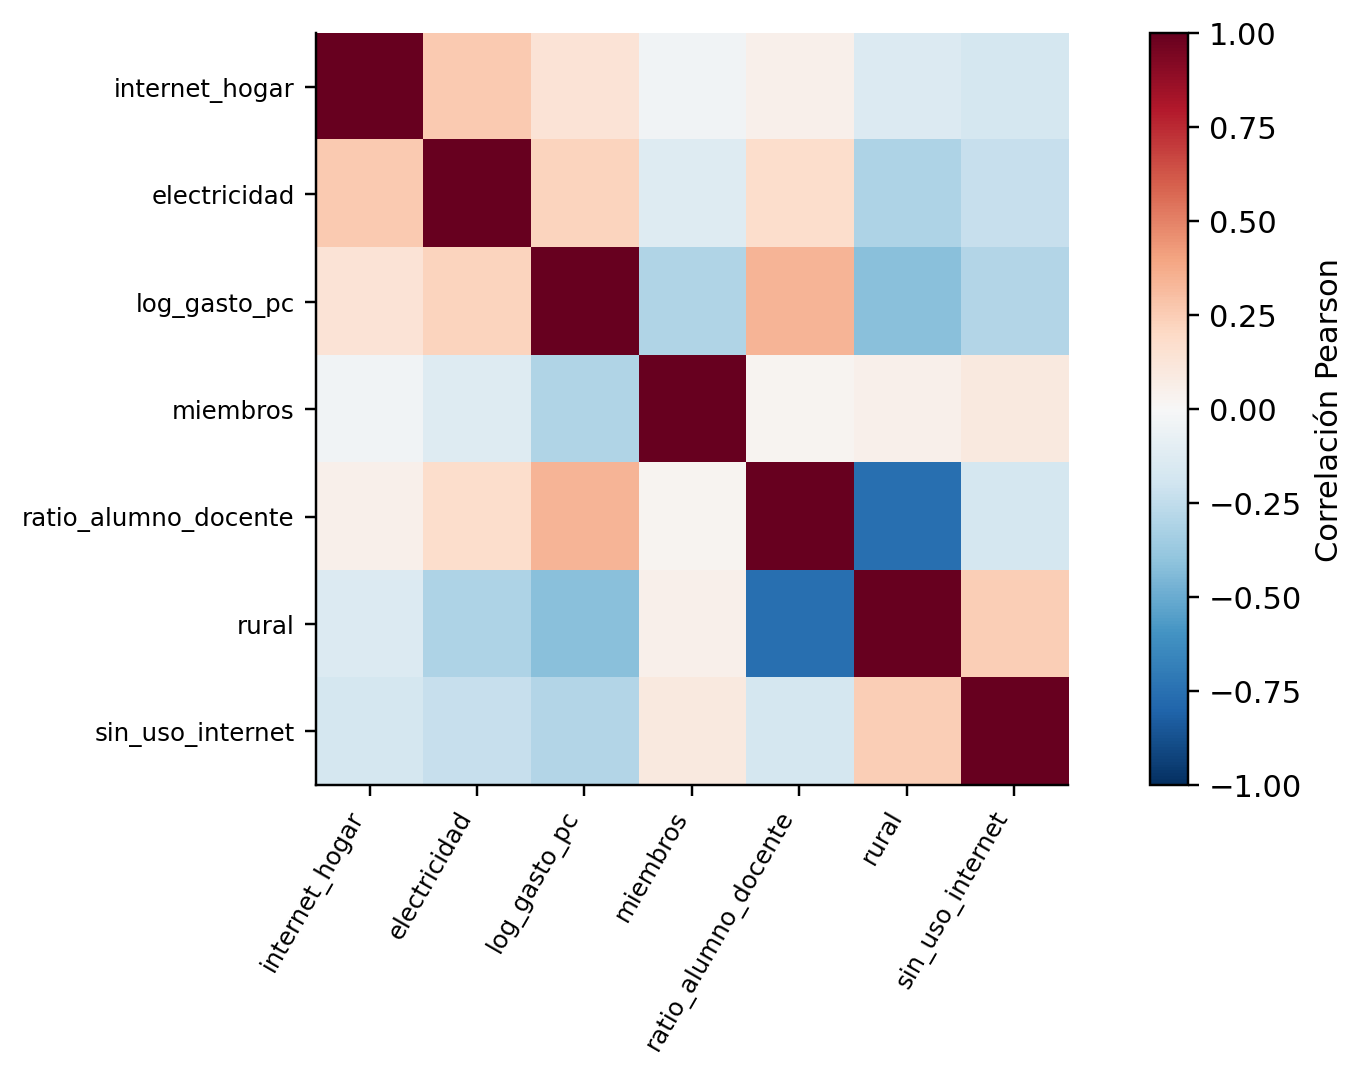

In [7]:
resumen_area=eda(m)
display(resumen_area)
display(pd.read_csv(TAB/'descriptivos.csv'))
for nombre in ['01_brecha_area.png','02_distribuciones.png','03_faltantes.png','04_correlaciones.png']:
 display(Image(filename=str(FIG/nombre),width=800))

## 5 Clusterización
Se comparan KMeans y GMM para k=2 a 6. Se evalúan silhouette, Davies-Bouldin, Calinski-Harabasz y ARI frente a tres semillas adicionales. Se exige ARI mínimo de 0,8 y se prioriza silhouette entre las soluciones estables. PCA se utiliza para visualizar, no para seleccionar k.

In [8]:
def cluster(m):
 cols=['internet_hogar','electricidad','log_gasto_pc','miembros','ratio_alumno_docente','rural']
 prep=Pipeline([('imputar',SimpleImputer(strategy='median')),('escalar',StandardScaler())]);z=prep.fit_transform(m[cols]);rows=[];models={}
 for method in ['KMeans','GMM']:
  for k in range(2,7):
   model=KMeans(n_clusters=k,n_init=15,random_state=42) if method=='KMeans' else GaussianMixture(n_components=k,n_init=3,reg_covar=1e-4,random_state=42)
   labels=model.fit_predict(z);s=silhouette_score(z,labels,sample_size=min(2000,len(z)),random_state=42)
   rows.append({'metodo':method,'k':k,'silhouette':s,'davies_bouldin':davies_bouldin_score(z,labels),'calinski_harabasz':calinski_harabasz_score(z,labels)})
   models[(method,k)]=(model,labels)
 scores=pd.DataFrame(rows).sort_values('silhouette',ascending=False)
 stability_all=[]
 for _,candidate in scores.iterrows():
  labels0=models[(candidate.metodo,int(candidate.k))][1];aris=[]
  for seed in [7,21,84]:
   other=KMeans(n_clusters=int(candidate.k),n_init=15,random_state=seed) if candidate.metodo=='KMeans' else GaussianMixture(n_components=int(candidate.k),n_init=3,reg_covar=1e-4,random_state=seed)
   ari=adjusted_rand_score(labels0,other.fit_predict(z));aris.append(ari)
   stability_all.append({'metodo':candidate.metodo,'k':int(candidate.k),'semilla':seed,'ARI':ari})
  scores.loc[(scores.metodo==candidate.metodo)&(scores.k==candidate.k),'ARI_min']=min(aris)
 table(pd.DataFrame(stability_all),'estabilidad_todos_clusters')
 stable=scores[scores.ARI_min>=.8];best=(stable if len(stable) else scores).iloc[0]
 scores['seleccionado']=(scores.metodo==best.metodo)&(scores.k==best.k)
 table(scores,'metricas_clusters');model,labels=models[(best.metodo,int(best.k))];m['cluster']=labels
 profile=m.groupby('cluster')[cols+['sin_uso_internet']].mean();profile.insert(0,'n',m.groupby('cluster').size());table(profile.reset_index(),'perfiles_clusters')
 for method,g in scores.groupby('metodo'):plt.plot(g.sort_values('k').k,g.sort_values('k').silhouette,'o-',label=method)
 plt.xlabel('Número de grupos');plt.ylabel('Silhouette');plt.legend();save('05_seleccion_clusters')
 xy=PCA(n_components=2).fit_transform(z);plt.figure(figsize=(7,4));plt.scatter(xy[:,0],xy[:,1],c=labels,s=8,cmap='tab10',alpha=.5);plt.xlabel('Componente principal 1');plt.ylabel('Componente principal 2');plt.title(f'{best.metodo} con {int(best.k)} grupos');save('06_clusters_pca')
 # Estabilidad frente a distintas inicializaciones, manteniendo los datos.
 stability=[]
 for seed in [7,21,84]:
  other=KMeans(n_clusters=int(best.k),n_init=15,random_state=seed) if best.metodo=='KMeans' else GaussianMixture(n_components=int(best.k),n_init=3,reg_covar=1e-4,random_state=seed)
  stability.append({'semilla':seed,'ARI':adjusted_rand_score(labels,other.fit_predict(z))})
 table(pd.DataFrame(stability),'estabilidad_clusters');return scores,profile

,metodo,k,silhouette,davies_bouldin,calinski_harabasz,ARI_min,seleccionado
5,GMM,2,0.501808,1.382846,4952.180443,0.109734,False
2,KMeans,4,0.435889,0.875255,8410.315402,1.000000,True
1,KMeans,3,0.412498,1.030998,7905.943470,1.000000,False
6,GMM,3,0.411603,1.034158,7839.169216,0.916236,False
7,GMM,4,0.407100,1.063285,5589.108574,0.921748,False
0,KMeans,2,0.388974,1.261088,8032.037420,0.999774,False
9,GMM,6,0.357217,0.953610,7573.462766,0.657909,False
3,KMeans,5,0.350995,0.995889,8801.929597,0.986192,False
8,GMM,5,0.349862,0.967333,8329.907570,0.995758,False
4,KMeans,6,0.329722,0.996410,8375.068214,0.814117,False


,n,internet_hogar,electricidad,log_gasto_pc,miembros,ratio_alumno_docente,rural,sin_uso_internet
cluster,,,,,,,,
0,11065,1.0,1.000000,6.517885,4.769001,17.521196,0.006326,0.171803
1,5008,1.0,1.000000,6.032535,4.776757,10.147485,0.988419,0.336062
2,997,1.0,0.000000,5.879832,5.508526,11.850814,0.868606,0.533601
3,737,0.0,0.595658,5.946337,5.138399,13.916239,0.678426,0.621438


,metodo,k,semilla,ARI
0,GMM,2,7,0.109734
1,GMM,2,21,1.000000
2,GMM,2,84,0.109734
3,KMeans,4,7,1.000000
4,KMeans,4,21,1.000000
5,KMeans,4,84,1.000000
6,KMeans,3,7,1.000000
7,KMeans,3,21,1.000000
8,KMeans,3,84,1.000000
9,GMM,3,7,0.942702


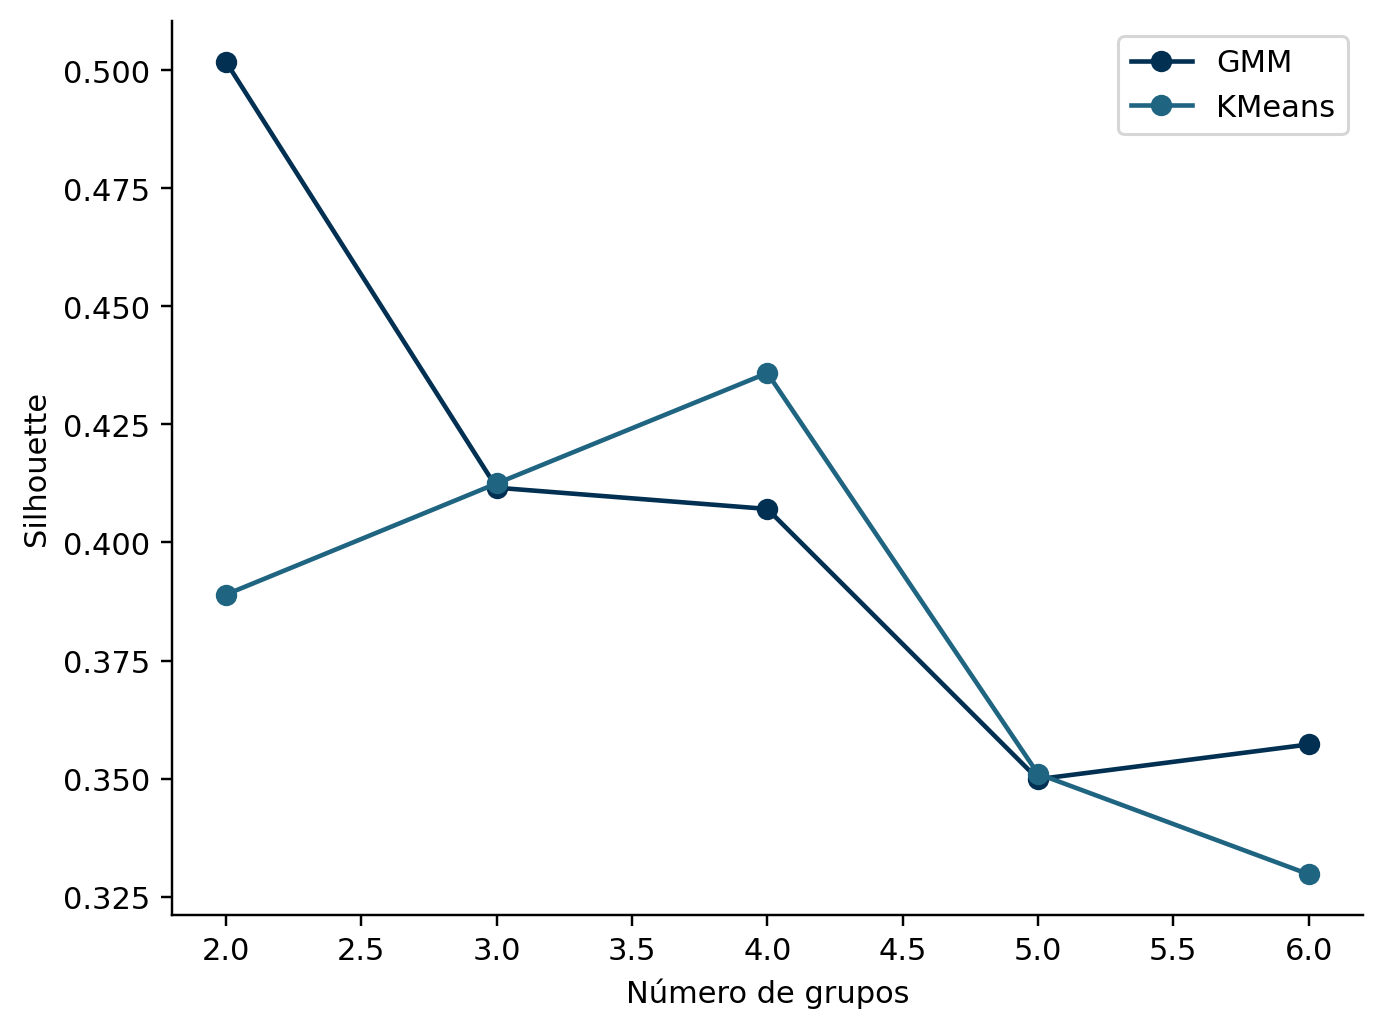

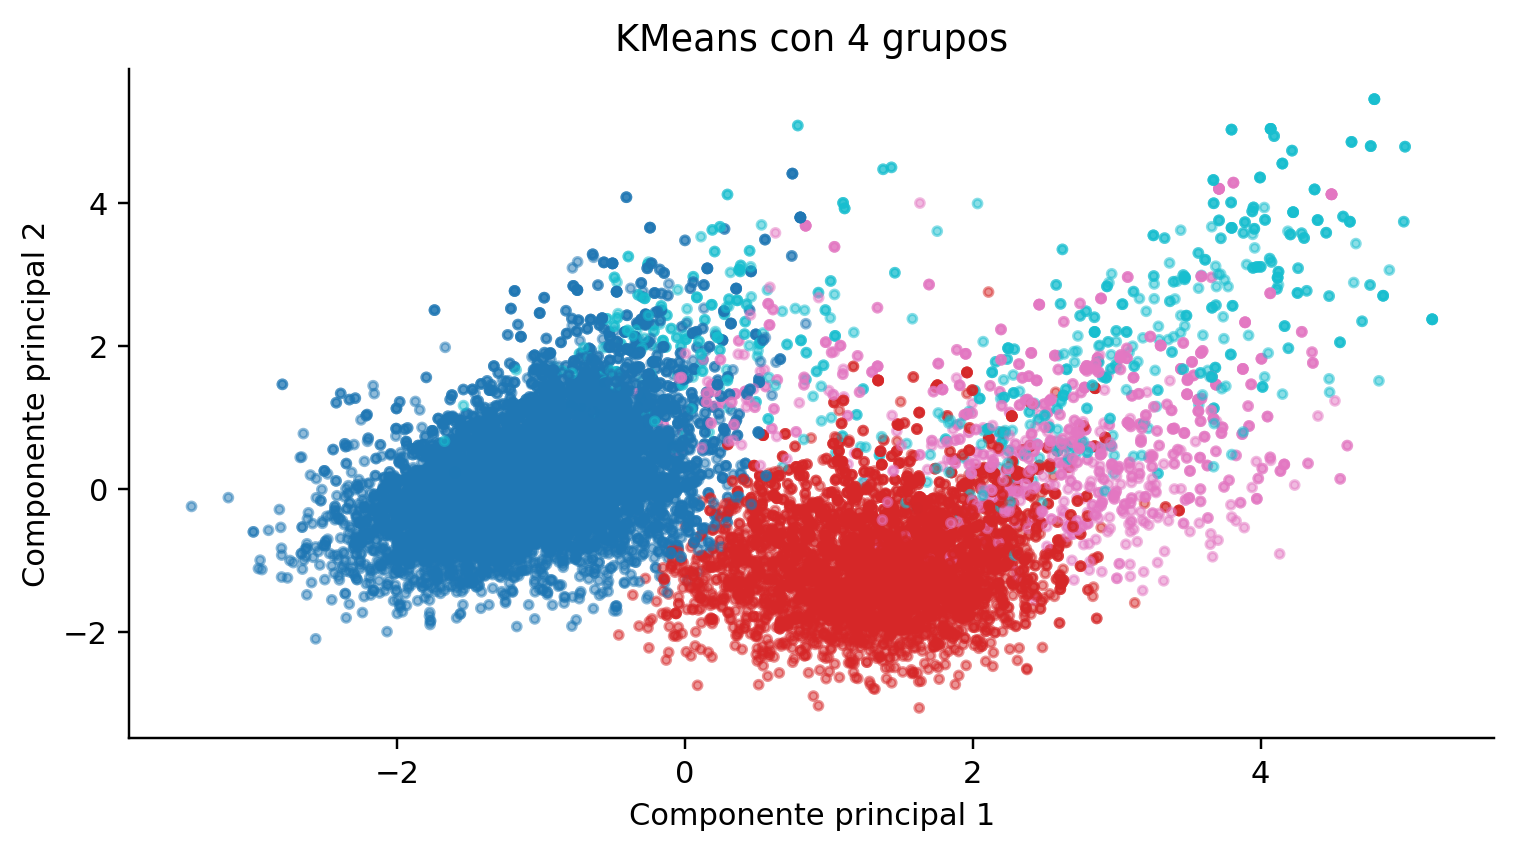

In [9]:
scores,profile=cluster(m)
display(scores)
display(profile)
display(pd.read_csv(TAB/'estabilidad_todos_clusters.csv'))
for nombre in ['05_seleccion_clusters.png','06_clusters_pca.png']:
 display(Image(filename=str(FIG/nombre),width=800))

## 6 Clasificación y explicabilidad
Se reserva prueba por CONGLOME con GroupShuffleSplit. Se comparan regresión logística, Random Forest, HistGradientBoosting y MLP mediante GroupKFold de tres folds, con F1 macro como criterio de selección. La preparación de variables se ajusta dentro de cada fold. El umbral de evaluación es 0,5. El MLP se compara sin pesos de clase, limitación documentada en el informe.

In [10]:
def explain(model,train,test,y,prob,name):
 import shap
 prep=model.named_steps['preparacion'];est=model.named_steps['modelo'];features=prep.get_feature_names_out();z=prep.transform(test);rng=np.random.default_rng(42)
 selected=rng.choice(len(z),min(180,len(z)),replace=False)
 good_hi=np.where((y.to_numpy()==1)&(prob>=.5))[0];good_lo=np.where((y.to_numpy()==0)&(prob<.5))[0]
 cases=[]
 if len(good_hi):cases.append(int(good_hi[np.argmax(prob[good_hi])]))
 if len(good_lo):cases.append(int(good_lo[np.argmin(prob[good_lo])]))
 selected=np.unique(np.r_[selected,cases]);zs=z[selected]
 if name in ['RandomForest','HistGradientBoosting']:
  ex=shap.TreeExplainer(est)(zs)
  if ex.values.ndim==3:ex=ex[:,:,1]
 elif name=='Logistica':ex=shap.LinearExplainer(est,prep.transform(train.sample(min(100,len(train)),random_state=42)))(zs)
 else:
  background=prep.transform(train.sample(min(40,len(train)),random_state=42));ex=shap.Explainer(lambda a:est.predict_proba(a)[:,1],background,algorithm='permutation',feature_names=features,seed=42)(zs,max_evals=2*zs.shape[1]+1)
 ex.feature_names=list(features)
 shap.plots.beeswarm(ex,max_display=10,show=False);save('09_shap_global')
 imp=np.abs(ex.values).mean(axis=0);order=np.argsort(imp)[::-1];table(pd.DataFrame({'variable':features,'media_abs_SHAP':imp}).sort_values('media_abs_SHAP',ascending=False),'importancia_shap')
 for j in range(2):shap.plots.scatter(ex[:,int(order[j])],color=ex[:,int(order[1-j])],show=False);save(f'10_shap_dependencia_{j+1}')
 for j,idx in enumerate(cases):
  position=int(np.where(selected==idx)[0][0]);shap.plots.waterfall(ex[position],max_display=10,show=False);save(f'11_shap_caso_{j+1}')
 table(pd.DataFrame([{'caso':j+1,'clase_real':int(y.iloc[idx]),'probabilidad_sin_uso':float(prob[idx])} for j,idx in enumerate(cases)]),'casos_shap')

In [11]:
def supervised(m):
 numeric=['edad','rural','internet_hogar','electricidad','log_gasto_pc','miembros','ratio_alumno_docente','proporcion_publica','latitud','longitud']
 if m.altitud.notna().any():numeric+=['altitud']
 cats=['sexo','lengua'];X=m[numeric+cats].copy();X[cats]=X[cats].fillna('Sin dato');y=m.sin_uso_internet.astype(int);groups=m.CONGLOME
 tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42).split(X,y,groups));assert not set(groups.iloc[tr])&set(groups.iloc[te])
 pd.DataFrame({'fila':np.arange(len(m)),'conjunto':np.where(np.isin(np.arange(len(m)),te),'prueba','entrenamiento')}).to_csv(DATA/'particiones.csv',index=False)
 preprocess=ColumnTransformer([('num',Pipeline([('imputar',SimpleImputer(strategy='median',add_indicator=True)),('escala',StandardScaler())]),numeric),('cat',Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cats)])
 ratio=float((y.iloc[tr]==0).sum()/max((y.iloc[tr]==1).sum(),1))
 specs={'Logistica':(LogisticRegression(max_iter=1500,class_weight='balanced',random_state=42),{'modelo__C':[.1,1]}),'RandomForest':(RandomForestClassifier(n_estimators=180,class_weight='balanced',random_state=42,n_jobs=2),{'modelo__min_samples_leaf':[5,15]}),'HistGradientBoosting':(HistGradientBoostingClassifier(max_iter=180,learning_rate=.05,class_weight='balanced',early_stopping=False,random_state=42),{'modelo__max_leaf_nodes':[7,15]}),'MLP':(MLPClassifier(hidden_layer_sizes=(32,16),max_iter=350,early_stopping=False,random_state=42),{'modelo__alpha':[.01,.1]})}
 fits={};cvrows=[]
 for name,(est,grid) in specs.items():
  print('MODELO',name,flush=True)
  search=GridSearchCV(Pipeline([('preparacion',preprocess),('modelo',est)]),grid,scoring='f1_macro',cv=GroupKFold(3),n_jobs=1,refit=True)
  search.fit(X.iloc[tr],y.iloc[tr],groups=groups.iloc[tr]);fits[name]=search.best_estimator_
  for i,params in enumerate(search.cv_results_['params']):cvrows.append({'modelo':name,'parametros':str(params),'F1_macro_CV':search.cv_results_['mean_test_score'][i],'desv_CV':search.cv_results_['std_test_score'][i]})
 cv=pd.DataFrame(cvrows);table(cv,'validacion_cruzada');winner=cv.loc[cv.F1_macro_CV.idxmax(),'modelo'];rows=[];probs={}
 fig,axs=plt.subplots(1,3,figsize=(13,3.8))
 for name,model in fits.items():
  prob=model.predict_proba(X.iloc[te])[:,1];pred=prob>=.5;probs[name]=prob
  rows.append({'modelo':name,'F1_macro':f1_score(y.iloc[te],pred,average='macro'),'precision':precision_score(y.iloc[te],pred,zero_division=0),'recall':recall_score(y.iloc[te],pred),'F1_positivo':f1_score(y.iloc[te],pred),'ROC_AUC':roc_auc_score(y.iloc[te],prob),'PR_AP':average_precision_score(y.iloc[te],prob),'Brier':brier_score_loss(y.iloc[te],prob)})
  fpr,tpr,_=roc_curve(y.iloc[te],prob);axs[0].plot(fpr,tpr,label=name)
  pr,re,_=precision_recall_curve(y.iloc[te],prob);axs[1].plot(re,pr,label=name)
  obs,predicted=calibration_curve(y.iloc[te],prob,n_bins=8,strategy='quantile');axs[2].plot(predicted,obs,'o-',label=name)
 axs[0].set(xlabel='Falsos positivos',ylabel='Verdaderos positivos',title='ROC');axs[1].set(xlabel='Recall',ylabel='Precisión',title='Precisión recall');axs[2].set(xlabel='Probabilidad predicha',ylabel='Frecuencia observada',title='Calibración');axs[2].plot([0,1],[0,1],'k--');axs[0].legend(fontsize=8);save('07_curvas_modelos')
 metrics=pd.DataFrame(rows);table(metrics,'metricas_prueba');pred=probs[winner]>=.5;cm=confusion_matrix(y.iloc[te],pred);ConfusionMatrixDisplay(cm,display_labels=['Usa internet','Sin uso']).plot(cmap='Blues',values_format='d');plt.title(winner);save('08_matriz_confusion');table(pd.DataFrame(cm,columns=['Predice uso','Predice sin uso']).reset_index(),'matriz_confusion')
 # Métricas ponderadas complementarias, sin confundirlas con inferencia de encuesta.
 w=m.peso.iloc[te].fillna(0).to_numpy();weighted={'ROC_AUC':roc_auc_score(y.iloc[te],probs[winner],sample_weight=w),'F1_macro':f1_score(y.iloc[te],pred,average='macro',sample_weight=w)}
 meta={'ganador_CV':winner,'n_train':len(tr),'n_test':len(te),'conglomerados_train':int(groups.iloc[tr].nunique()),'conglomerados_test':int(groups.iloc[te].nunique()),'solapamiento':0,'prevalencia_train':float(y.iloc[tr].mean()),'prevalencia_test':float(y.iloc[te].mean()),'matriz':cm.tolist(),'ponderadas':weighted,'variables':numeric+cats}
 (TAB/'modelo_metadata.json').write_text(json.dumps(meta,indent=2,ensure_ascii=False),encoding='utf8')
 explain(fits[winner],X.iloc[tr],X.iloc[te],y.iloc[te],probs[winner],winner)
 return metrics,meta

MODELO Logistica
MODELO RandomForest
MODELO HistGradientBoosting
MODELO MLP
{
  "ganador_CV": "RandomForest",
  "n_train": 14411,
  "n_test": 3396,
  "conglomerados_train": 3288,
  "conglomerados_test": 822,
  "solapamiento": 0,
  "prevalencia_train": 0.2622302407882867,
  "prevalencia_test": 0.23409893992932862,
  "matriz": [
    [
      2152,
      449
    ],
    [
      268,
      527
    ]
  ],
  "ponderadas": {
    "ROC_AUC": 0.7821365048156822,
    "F1_macro": 0.6920320122475476
  },
  "variables": [
    "edad",
    "rural",
    "internet_hogar",
    "electricidad",
    "log_gasto_pc",
    "miembros",
    "ratio_alumno_docente",
    "proporcion_publica",
    "latitud",
    "longitud",
    "altitud",
    "sexo",
    "lengua"
  ]
}


,modelo,parametros,F1_macro_CV,desv_CV
0,Logistica,{'modelo__C': 0.1},0.729638,0.010535
1,Logistica,{'modelo__C': 1},0.729842,0.011416
2,RandomForest,{'modelo__min_samples_leaf': 5},0.743409,0.012847
3,RandomForest,{'modelo__min_samples_leaf': 15},0.736784,0.010220
4,HistGradientBoosting,{'modelo__max_leaf_nodes': 7},0.728395,0.003315
5,HistGradientBoosting,{'modelo__max_leaf_nodes': 15},0.731339,0.007146
6,MLP,{'modelo__alpha': 0.01},0.721487,0.003163
7,MLP,{'modelo__alpha': 0.1},0.725988,0.007597


,modelo,F1_macro,precision,recall,F1_positivo,ROC_AUC,PR_AP,Brier
0,Logistica,0.708858,0.489950,0.735849,0.588235,0.830480,0.630623,0.162152
1,RandomForest,0.726172,0.539959,0.662893,0.595144,0.831267,0.637147,0.145359
2,HistGradientBoosting,0.716740,0.498749,0.752201,0.599799,0.840848,0.651042,0.155765
3,MLP,0.721729,0.672043,0.471698,0.554324,0.828255,0.631848,0.129865


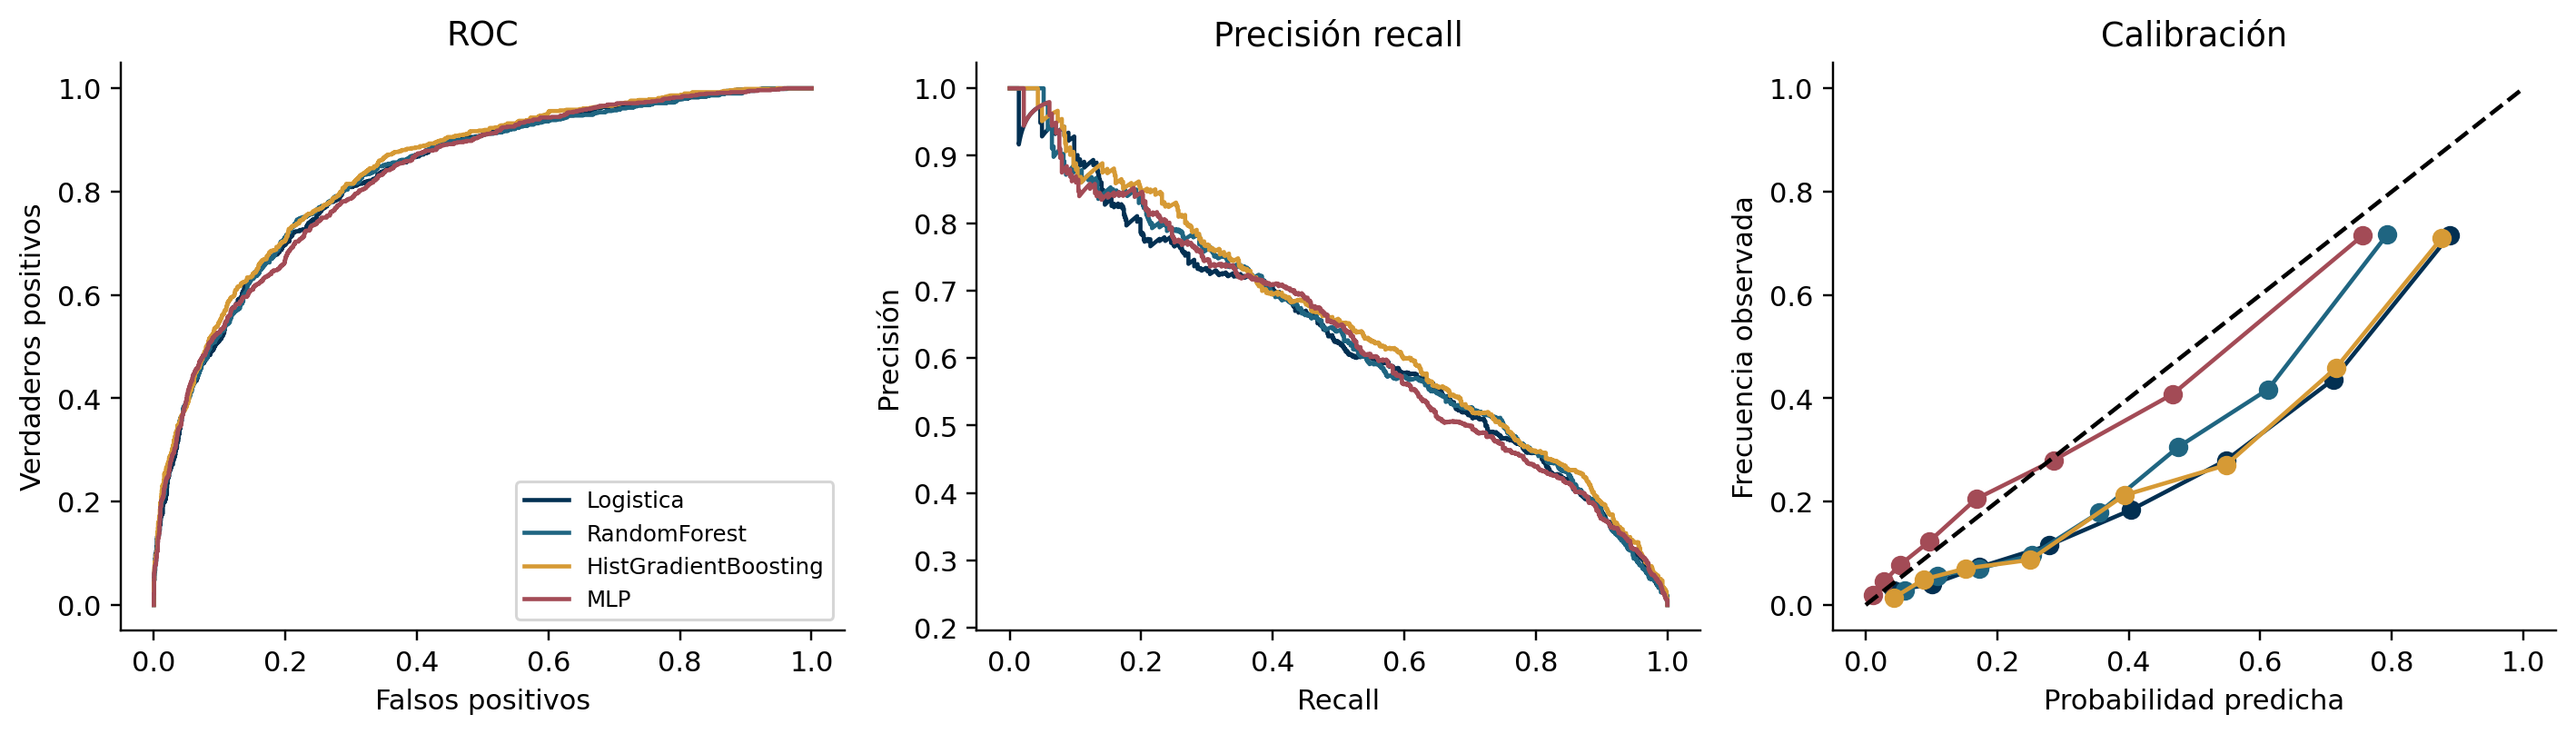

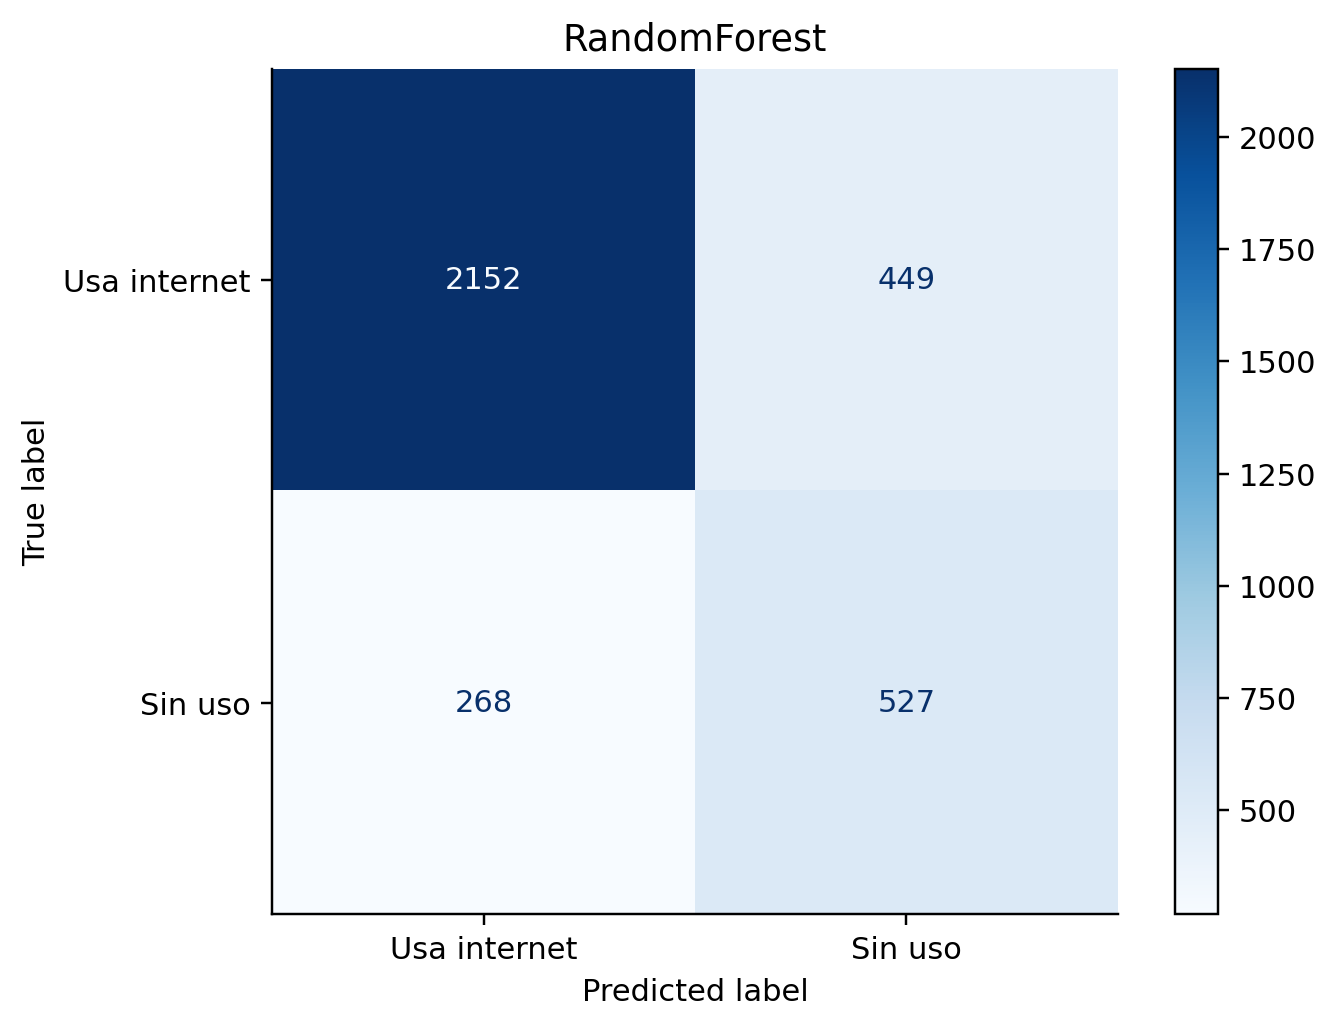

In [12]:
metrics,meta=supervised(m)
display(pd.read_csv(TAB/'validacion_cruzada.csv'))
display(metrics)
print(json.dumps(meta,ensure_ascii=False,indent=2))
for nombre in ['07_curvas_modelos.png','08_matriz_confusion.png']:
 display(Image(filename=str(FIG/nombre),width=900))

## 7 Resultados SHAP
Las explicaciones se calculan sobre una selección reproducible de casos de prueba y dos extremos correctos. La importancia media absoluta mide magnitud de contribución, no efecto causal. Las continuas aparecen estandarizadas; los casos no incluyen identificadores.

,variable,media_abs_SHAP
0,num__edad,0.164111
1,num__log_gasto_pc,0.076453
2,num__proporcion_publica,0.034771
3,num__rural,0.032739
4,num__latitud,0.021087
5,num__electricidad,0.016831
6,num__longitud,0.015653
7,num__ratio_alumno_docente,0.014966
8,num__altitud,0.014445
9,cat__lengua_4,0.013856


,caso,clase_real,probabilidad_sin_uso
0,1,1,0.993928
1,2,0,0.017919


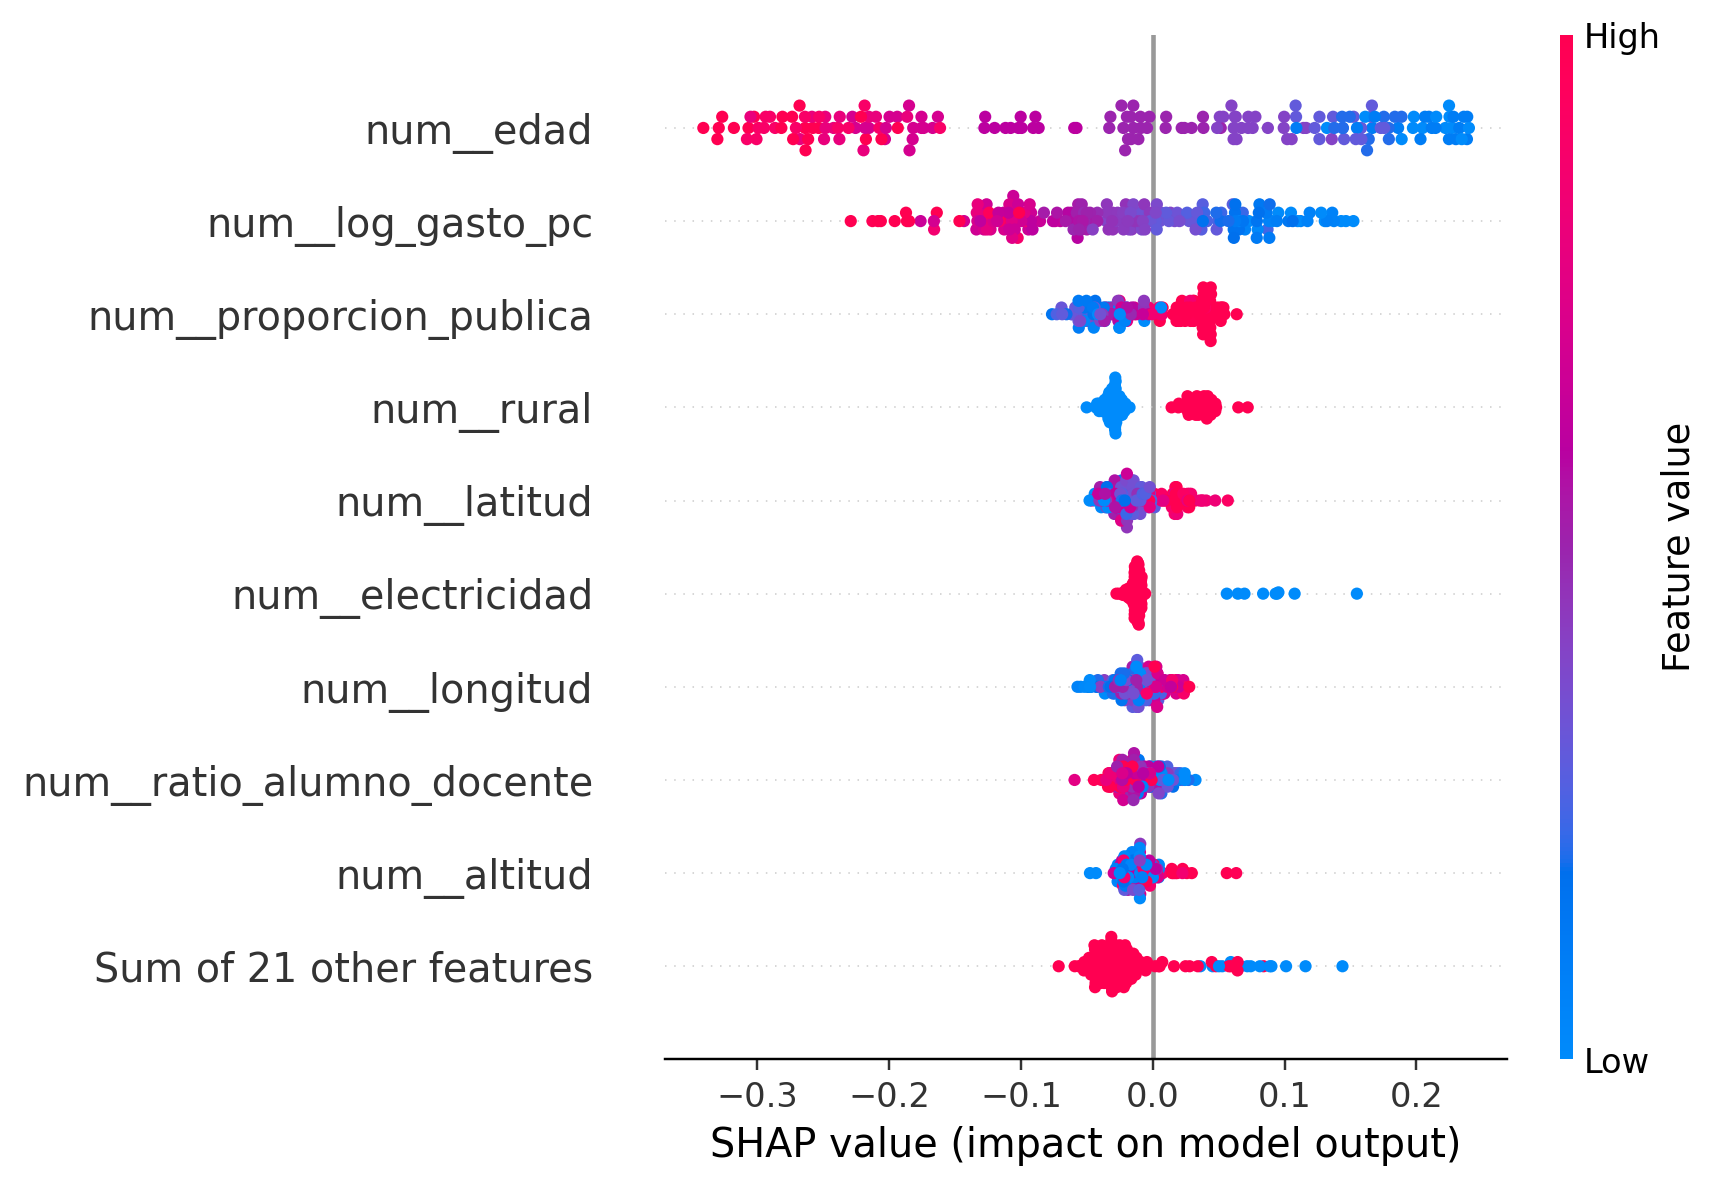

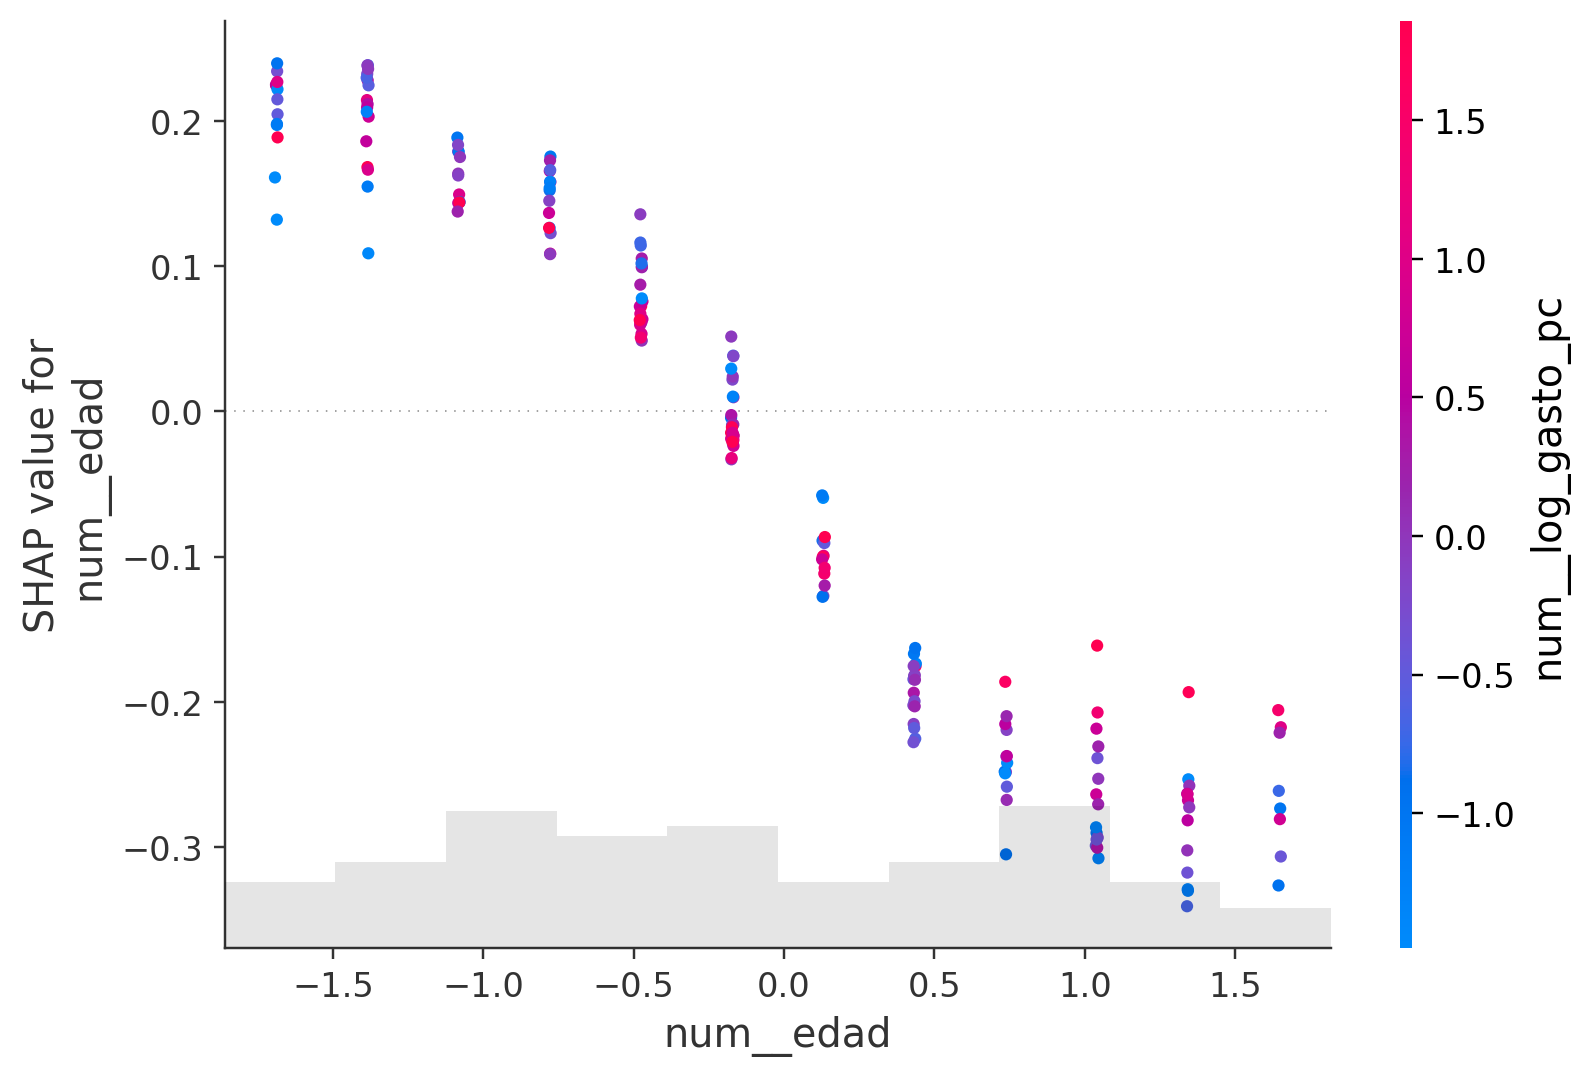

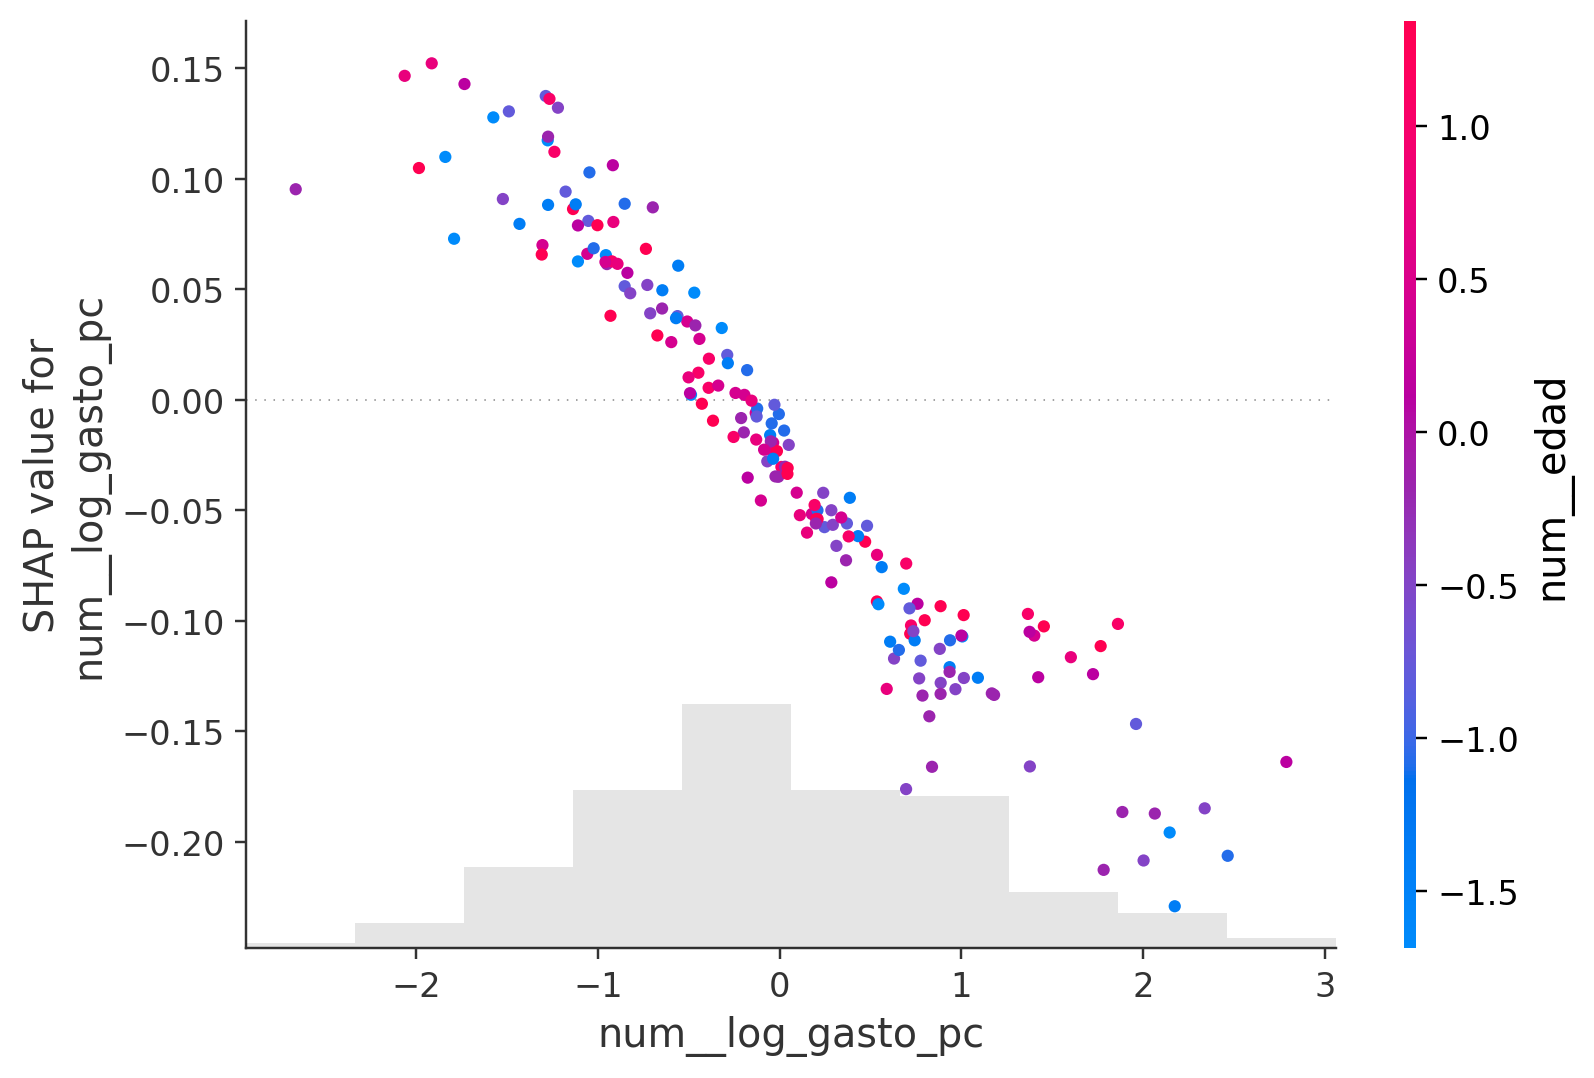

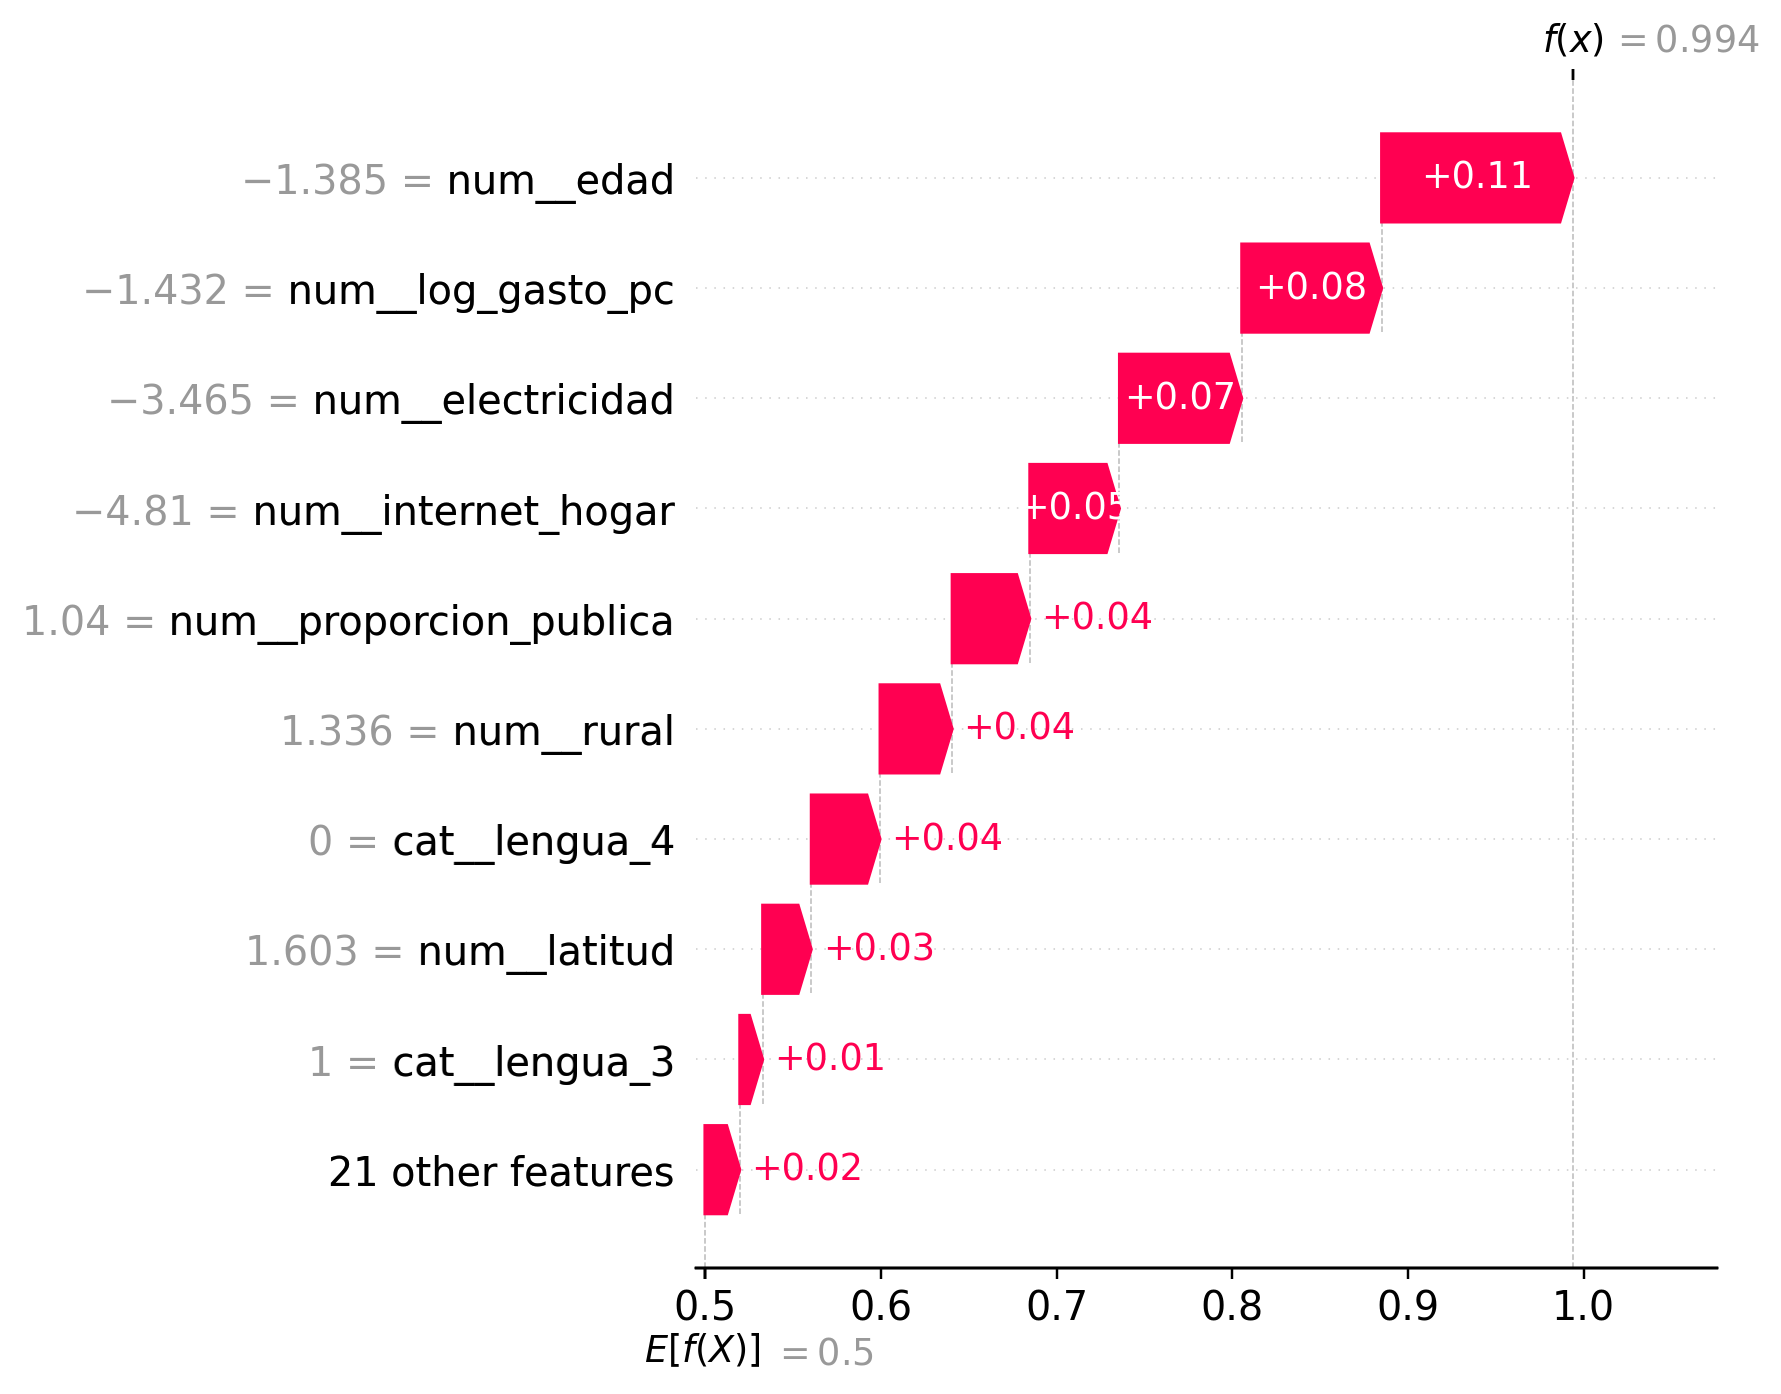

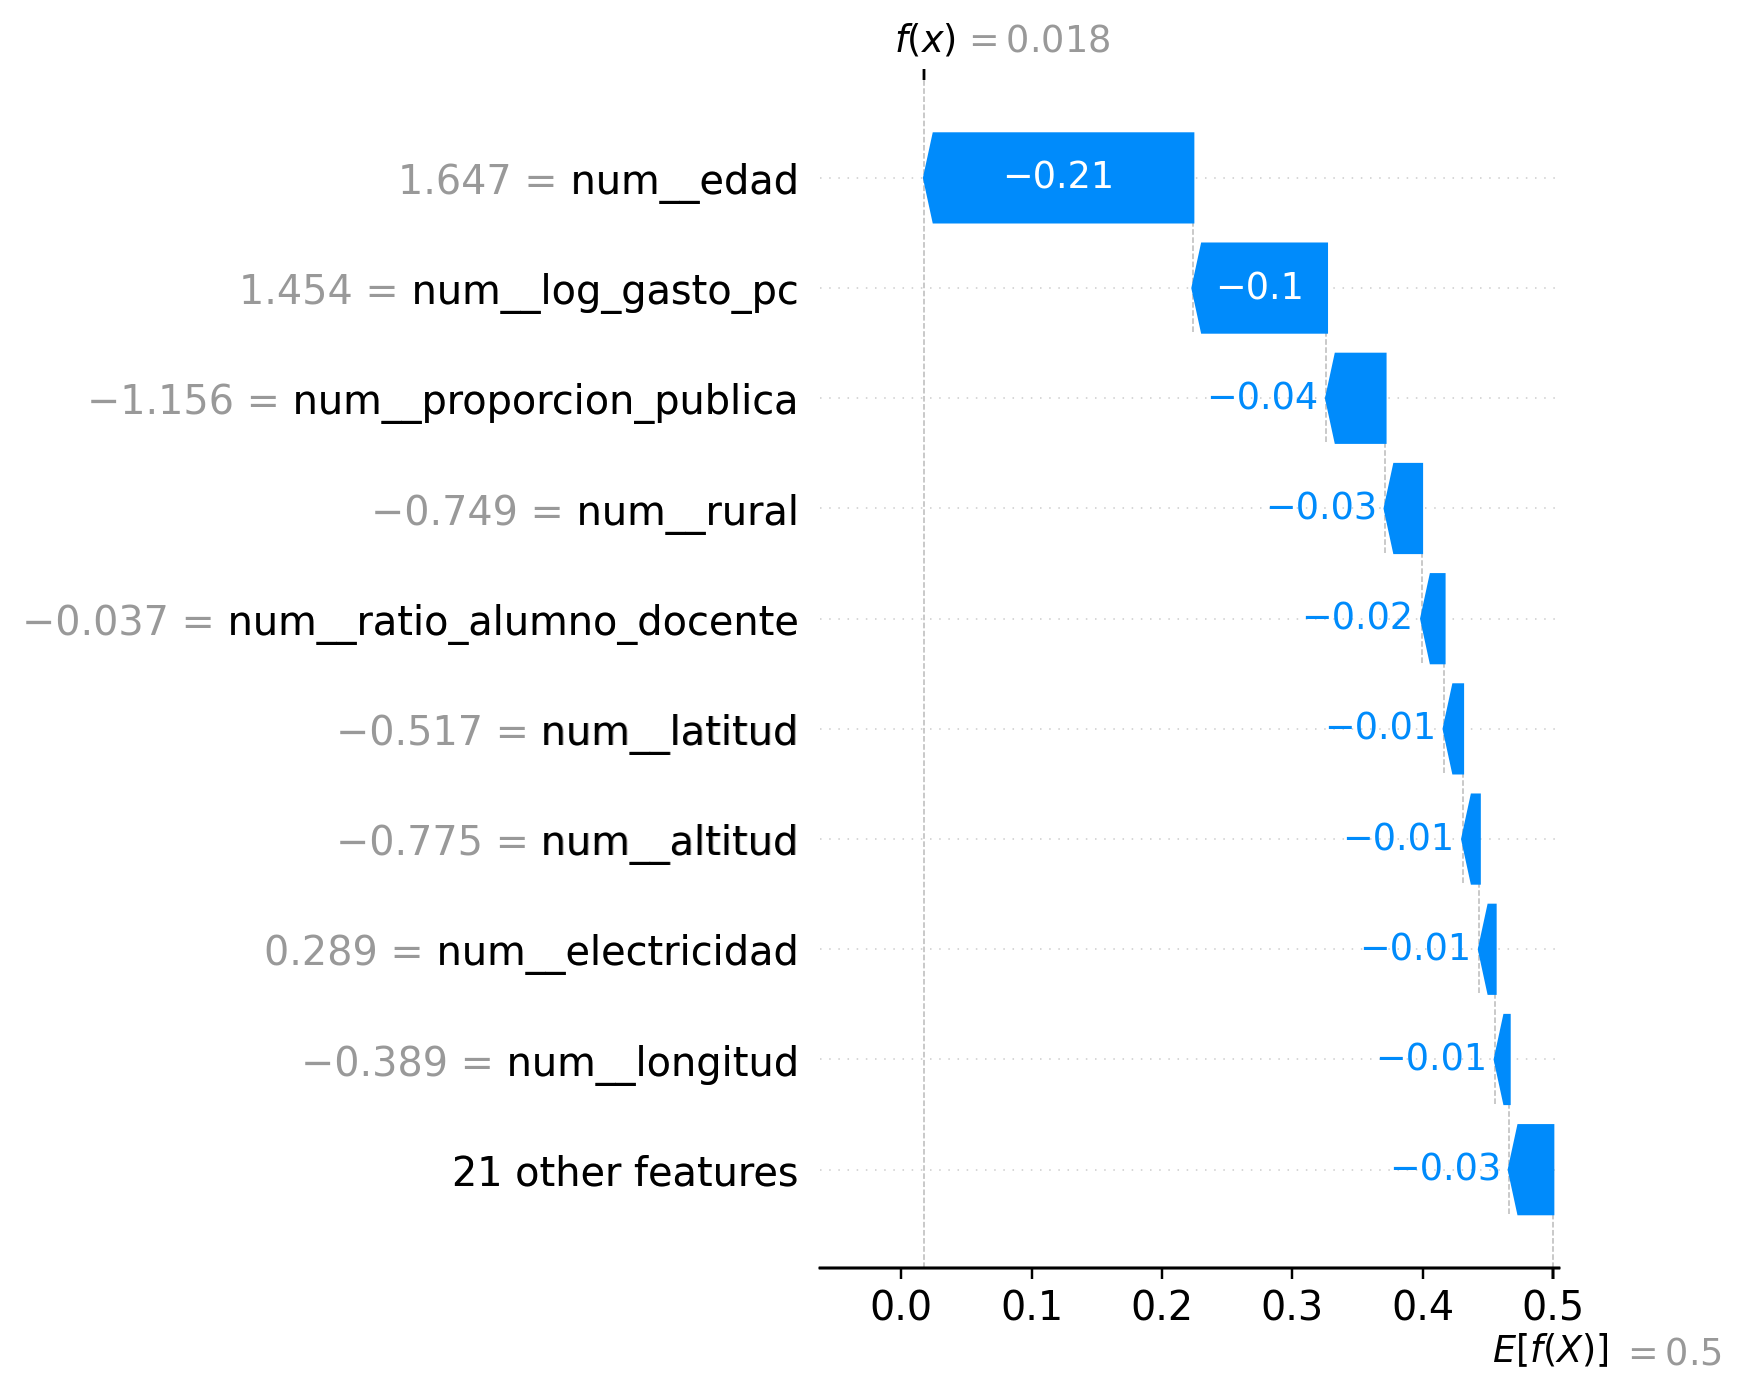

In [13]:
display(pd.read_csv(TAB/'importancia_shap.csv').head(10))
display(pd.read_csv(TAB/'casos_shap.csv'))
for nombre in ['09_shap_global.png','10_shap_dependencia_1.png','10_shap_dependencia_2.png','11_shap_caso_1.png','11_shap_caso_2.png']:
 display(Image(filename=str(FIG/nombre),width=800))

## 8 Exportación y comprobaciones
Se guarda la base procesada y el resumen para cotejarlos con el informe. Las claves de microdatos se excluyen del paquete público para GitHub. Los datos crudos se conservan sin modificar.

In [14]:
m.to_csv(DATA/'dataset_enaho_escale_2025.csv',index=False,encoding='utf-8-sig')
summary={'n':len(m),'hogares':int(m[['CONGLOME','VIVIENDA','HOGAR']].drop_duplicates().shape[0]),'distritos':int(m.UBIGEO.nunique()),'conglomerados':int(m.CONGLOME.nunique()),'sin_uso':float(m.sin_uso_internet.mean()),'sin_uso_ponderado':float(np.average(m.sin_uso_internet,weights=m.peso.fillna(0))),'sin_contexto':int(m.ratio_alumno_docente.isna().sum()),'cluster':scores.loc[scores.seleccionado].iloc[0].to_dict(),**meta}
(TAB/'resumen.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf8');print(json.dumps(summary,ensure_ascii=False,indent=2),flush=True)
assert meta['solapamiento']==0
assert len(m)==17807
print('Comprobaciones completadas: población y separación por conglomerado correctas.')

{
  "n": 17807,
  "hogares": 11486,
  "distritos": 1131,
  "conglomerados": 4110,
  "sin_uso": 0.25686527769978096,
  "sin_uso_ponderado": 0.223976027695193,
  "sin_contexto": 367,
  "cluster": {
    "metodo": "KMeans",
    "k": 4,
    "silhouette": 0.435888929009099,
    "davies_bouldin": 0.8752545239412423,
    "calinski_harabasz": 8410.315401656131,
    "ARI_min": 1.0,
    "seleccionado": true
  },
  "ganador_CV": "RandomForest",
  "n_train": 14411,
  "n_test": 3396,
  "conglomerados_train": 3288,
  "conglomerados_test": 822,
  "solapamiento": 0,
  "prevalencia_train": 0.2622302407882867,
  "prevalencia_test": 0.23409893992932862,
  "matriz": [
    [
      2152,
      449
    ],
    [
      268,
      527
    ]
  ],
  "ponderadas": {
    "ROC_AUC": 0.7821365048156822,
    "F1_macro": 0.6920320122475476
  },
  "variables": [
    "edad",
    "rural",
    "internet_hogar",
    "electricidad",
    "log_gasto_pc",
    "miembros",
    "ratio_alumno_docente",
    "proporcion_publica",
    

## 9 Bases limpias de todas las fuentes utilizadas
Se exportan los cuatro módulos ENAHO del proyecto, los servicios escolares, el contexto distrital y la base integrada. Se conservan faltantes legítimos y se excluyen datos personales de contacto.

In [15]:
# Exportar todas las bases fuente utilizadas, además de la tabla del modelo.
fuentes=[]
for nombre,frame in dfs.items():
 limpio=frame.copy()
 for columna in limpio.select_dtypes(include=['object','str']).columns:
  limpio[columna]=limpio[columna].astype('string').str.strip().replace('',pd.NA)
 assert limpio['AÑO'].eq('2025').all()
 llaves=['CONGLOME','VIVIENDA','HOGAR']+(['CODPERSO'] if nombre in ['200','300'] else [])
 assert not limpio.duplicated(llaves).any()
 archivo=f'enaho_{nombre}_2025.csv' if nombre!='sumaria' else 'sumaria_2025.csv'
 limpio.to_csv(DATA/archivo,index=False,encoding='utf-8-sig')
 fuentes.append({'archivo':archivo,'filas':len(limpio),'columnas':len(limpio.columns),'alcance':'Corte 2025 y variables utilizadas en el proyecto'})
cols=['COD_MOD','ANEXO','CODLOCAL','NIV_MOD','GESTION','AREA_CENSO','CODGEO','D_DPTO','D_PROV','D_DIST','NLAT_IE','NLONG_IE','TALUM','TDOC','ESTADO']
escuela=pad.loc[pad.ESTADO.eq('1') & pad.NIV_MOD.isin(['B0','F0']),cols].copy()
for c in escuela.select_dtypes(include=['object','str']).columns:escuela[c]=escuela[c].astype('string').str.strip().replace('',pd.NA)
for c in ['TALUM','TDOC']:escuela[c]=pd.to_numeric(escuela[c],errors='coerce');escuela.loc[escuela[c]<0,c]=np.nan
escuela['NLAT_IE']=pd.to_numeric(escuela.NLAT_IE,errors='coerce');escuela['NLONG_IE']=pd.to_numeric(escuela.NLONG_IE,errors='coerce')
escuela.loc[~escuela.NLAT_IE.between(-19,0),'NLAT_IE']=np.nan;escuela.loc[~escuela.NLONG_IE.between(-82,-68),'NLONG_IE']=np.nan
assert not escuela.duplicated(['COD_MOD','ANEXO']).any()
escuela.to_csv(DATA/'escale_servicios_2025.csv',index=False,encoding='utf-8-sig')
fuentes.append({'archivo':'escale_servicios_2025.csv','filas':len(escuela),'columnas':len(escuela.columns),'alcance':'Servicios activos de primaria y secundaria; sin datos personales de contacto'})
contexto=pd.read_csv(TAB/'contexto_distrital_escale.csv',dtype={'CODGEO':str})
contexto.to_csv(DATA/'escale_contexto_distrital_2025.csv',index=False,encoding='utf-8-sig')
fuentes.append({'archivo':'escale_contexto_distrital_2025.csv','filas':len(contexto),'columnas':len(contexto.columns),'alcance':'Agregación por distrito y área'})
fuentes.append({'archivo':'dataset_enaho_escale_2025.csv','filas':len(m),'columnas':len(m.columns),'alcance':'Base integrada final de estudiantes, con clústeres'})
inventario=pd.DataFrame(fuentes);inventario.to_csv(DATA/'inventario_data_limpia.csv',index=False,encoding='utf-8-sig');display(inventario)
(DATA/'LEEME.md').write_text('''# Datos limpios del proyecto

Incluye los cortes 2025 de todas las fuentes utilizadas: ENAHO 100, 200, 300 y Sumaria; servicios ESCALE de primaria y secundaria; agregación distrital y base integrada. Las bases fuente contienen las variables seleccionadas para este proyecto y mantienen los casos previos al filtro de edad y asistencia. No se presentan como una limpieza de todos los módulos ajenos al análisis (por ejemplo salud y empleo).

La base integrada tiene 17 807 estudiantes. Los datos fuente conservan ausencias y saltos legítimos; la imputación de los predictores pertenece a cada fold del modelo. Los identificadores se mantienen como texto. No hay nombres personales ni teléfonos de directores en la exportación ESCALE.

El diccionario y el inventario describen los archivos. Particiones.csv documenta entrenamiento y prueba. Estos microdatos se entregan para revisión académica y están excluidos del contenido público de GitHub.
''',encoding='utf8')


,archivo,filas,columnas,alcance
0,enaho_100_2025.csv,44599,17,Corte 2025 y variables utilizadas en el proyecto
1,enaho_200_2025.csv,115145,15,Corte 2025 y variables utilizadas en el proyecto
2,enaho_300_2025.csv,106958,18,Corte 2025 y variables utilizadas en el proyecto
3,sumaria_2025.csv,33702,13,Corte 2025 y variables utilizadas en el proyecto
4,escale_servicios_2025.csv,54038,15,Servicios activos de primaria y secundaria; si...
5,escale_contexto_distrital_2025.csv,2439,9,Agregación por distrito y área
6,dataset_enaho_escale_2025.csv,17807,56,"Base integrada final de estudiantes, con clúst..."


## 10 EDA por edad sexo área y conexión
Este complemento forma parte del mismo notebook. Calcula tasas muestrales y ponderadas sobre la base integrada.

     dimension   grupo     n  sin_uso_muestra  sin_uso_ponderado
    grupo_edad   6 a 8  4025         0.515031           0.455470
    grupo_edad  9 a 11  4563         0.334648           0.290594
    grupo_edad 12 a 14  4978         0.149257           0.130662
    grupo_edad 15 a 17  4241         0.054468           0.054390
         rural       0 11421         0.176867           0.180456
         rural       1  6386         0.399937           0.392922
internet_hogar       0   737         0.621438           0.460274
internet_hogar       1 17070         0.241125           0.215586
          sexo       1  9018         0.262364           0.232645
          sexo       2  8789         0.251223           0.215149


,dimension,grupo,n,sin_uso_muestra,sin_uso_ponderado
0,grupo_edad,6 a 8,4025,0.515031,0.455470
1,grupo_edad,9 a 11,4563,0.334648,0.290594
2,grupo_edad,12 a 14,4978,0.149257,0.130662
3,grupo_edad,15 a 17,4241,0.054468,0.054390
4,rural,0,11421,0.176867,0.180456
5,rural,1,6386,0.399937,0.392922
6,internet_hogar,0,737,0.621438,0.460274
7,internet_hogar,1,17070,0.241125,0.215586
8,sexo,1,9018,0.262364,0.232645
9,sexo,2,8789,0.251223,0.215149


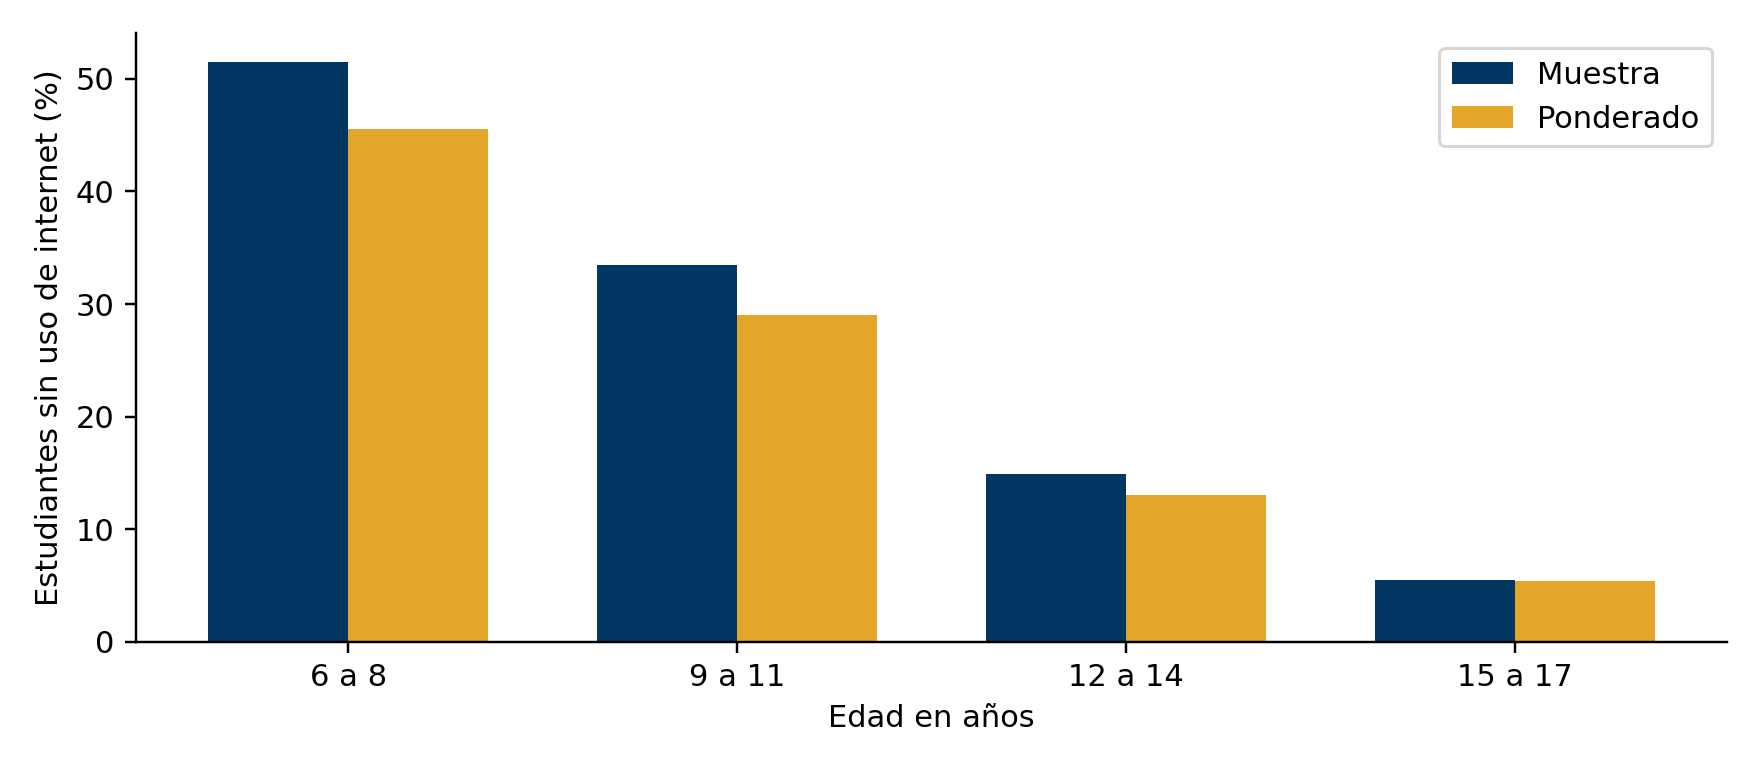

In [16]:
"""EDA complementario reproducible sobre la base analítica exportada."""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
# ROOT se definió en la primera celda
d=pd.read_csv(DATA/'dataset_enaho_escale_2025.csv')
d['grupo_edad']=pd.cut(d.edad,[5,8,11,14,17],labels=['6 a 8','9 a 11','12 a 14','15 a 17'])
rows=[]
for group in ['grupo_edad','rural','internet_hogar','sexo']:
 for value,g in d.groupby(group,observed=True):
  valid=g.peso.notna() & g.peso.gt(0)
  rows.append({'dimension':group,'grupo':str(value),'n':len(g),'sin_uso_muestra':g.sin_uso_internet.mean(),'sin_uso_ponderado':np.average(g.loc[valid,'sin_uso_internet'],weights=g.loc[valid,'peso'])})
t=pd.DataFrame(rows);t.to_csv(TAB/'eda_complementario.csv',index=False,encoding='utf-8-sig')
a=t[t.dimension.eq('grupo_edad')]
fig,ax=plt.subplots(figsize=(8,3.5));x=np.arange(len(a));ax.bar(x-.18,a.sin_uso_muestra*100,.36,label='Muestra',color='#033763');ax.bar(x+.18,a.sin_uso_ponderado*100,.36,label='Ponderado',color='#E4A62A');ax.set_xticks(x,a.grupo);ax.set_xlabel('Edad en años');ax.set_ylabel('Estudiantes sin uso de internet (%)');ax.legend();fig.tight_layout();fig.savefig(FIG/'12_brecha_por_edad.png',dpi=220);plt.close(fig)
print(t.to_string(index=False))

display(t)
display(Image(filename=str(FIG/'12_brecha_por_edad.png'),width=800))

## 11 Diagrama calidad y diccionario
Se generan las evidencias auxiliares y el diccionario desde las mismas bases procesadas. Todo su código se conserva aquí; no se ejecutan scripts externos.

{'numpy': '2.3.5', 'pandas': '3.0.1', 'scipy': '1.17.1', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9', 'shap': '0.54.1', 'dbfread': '2.0.7', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}


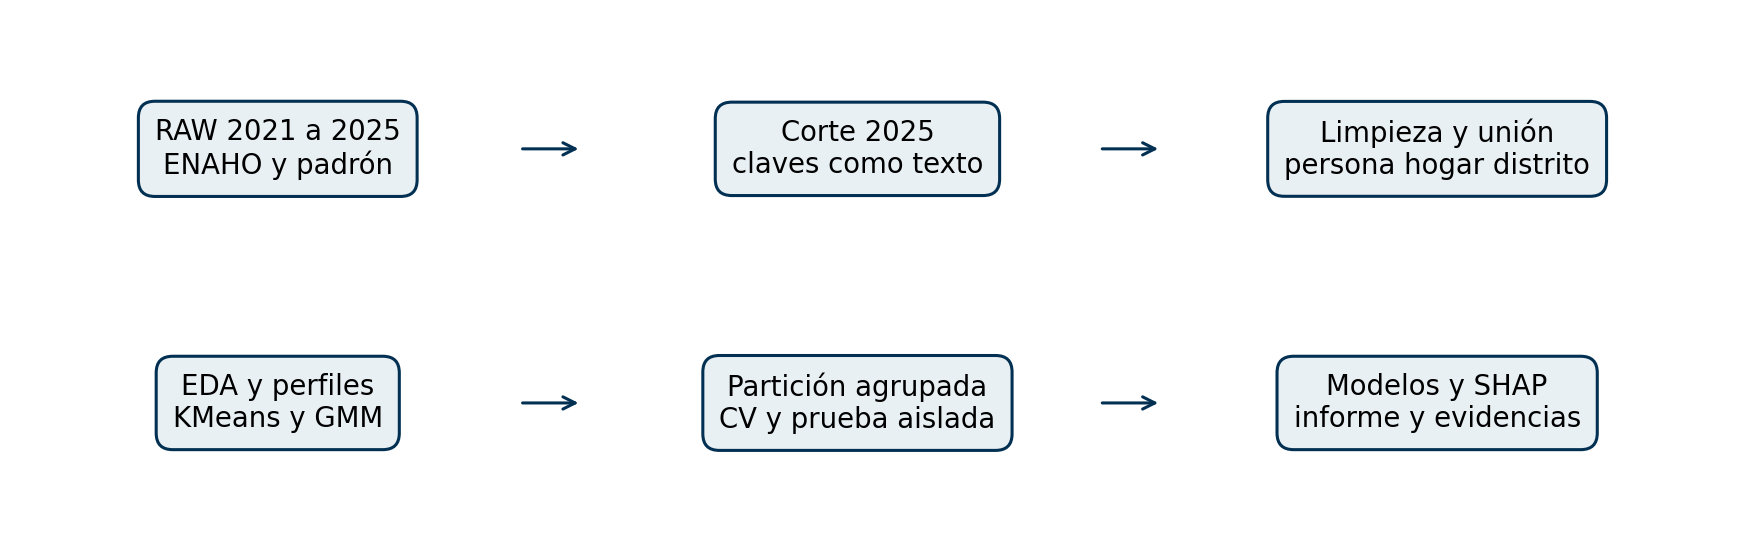

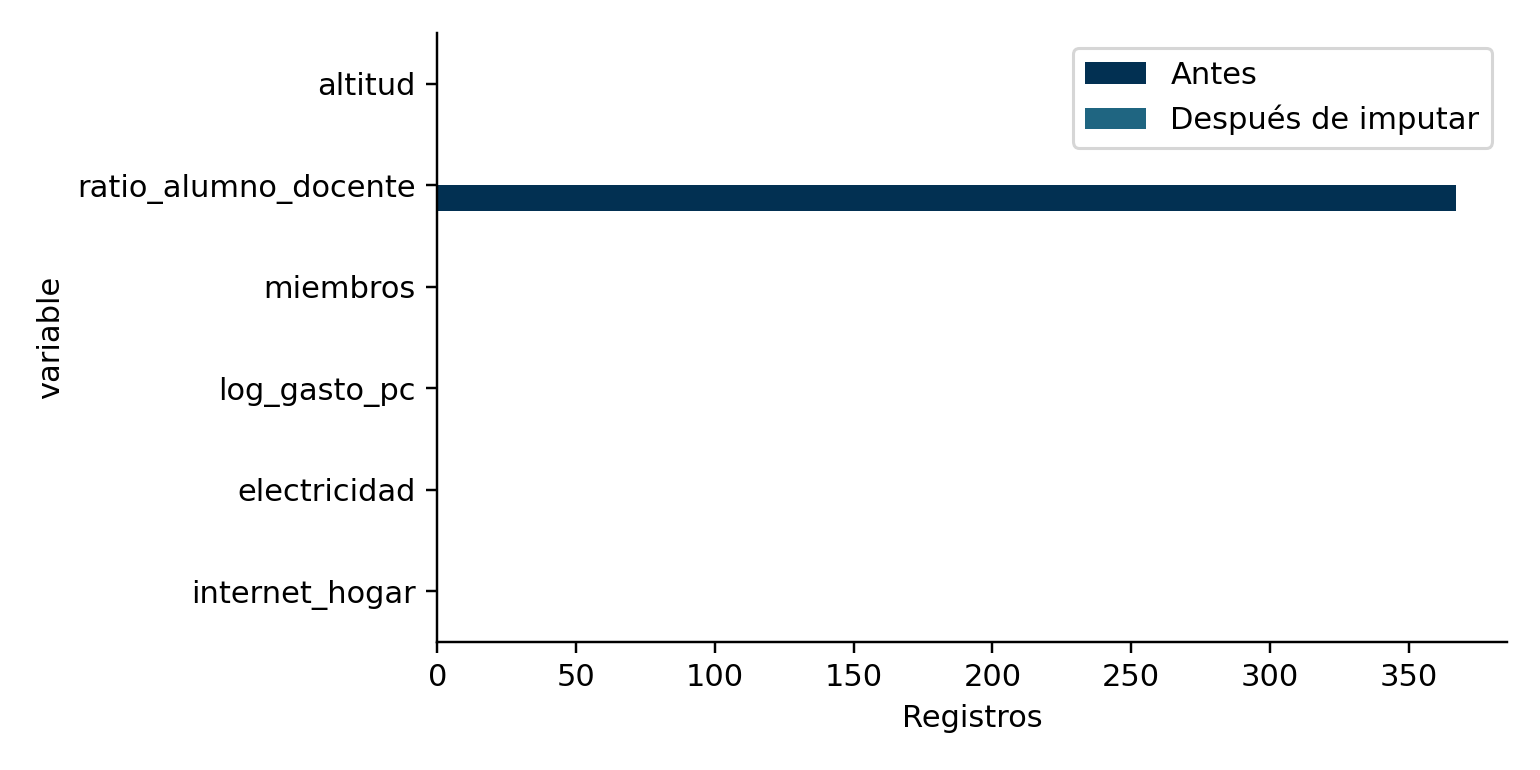

In [17]:
from pathlib import Path
import sys
import pandas as pd,numpy as np,matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from importlib.metadata import version
r=ROOT;t=TAB;f=FIG
d=pd.read_csv(DATA/'dataset_enaho_escale_2025.csv',dtype={'CONGLOME':str,'UBIGEO':str,'VIVIENDA':str,'HOGAR':str,'CODPERSO':str})
# Calidad antes y después: mediana ilustrativa de entrenamiento exclusivamente.
p=pd.read_csv(DATA/'particiones.csv');train=p.conjunto.eq('entrenamiento')
cols=['internet_hogar','electricidad','log_gasto_pc','miembros','ratio_alumno_docente','altitud']
a=d[cols].isna().sum();med=d.loc[train,cols].median();b=d[cols].fillna(med).isna().sum()
quality=pd.DataFrame({'variable':cols,'faltantes_antes':a.values,'faltantes_despues_imputacion':b.values,'mediana_train':med.values});quality.to_csv(t/'calidad_preprocesamiento.csv',index=False)
quality.set_index('variable')[['faltantes_antes','faltantes_despues_imputacion']].plot.barh(figsize=(7,3.5));plt.xlabel('Registros');plt.legend(['Antes','Después de imputar']);plt.tight_layout();plt.savefig(f/'00_calidad_antes_despues.png',dpi=220);plt.close()
# Flujo visual
fig,ax=plt.subplots(figsize=(10,3));ax.axis('off');texts=['RAW 2021 a 2025\nENAHO y padrón','Corte 2025\nclaves como texto','Limpieza y unión\npersona hogar distrito','EDA y perfiles\nKMeans y GMM','Partición agrupada\nCV y prueba aislada','Modelos y SHAP\ninforme y evidencias']
for i,txt in enumerate(texts):
 x=(i%3)*.34;y=.75-(i//3)*.5
 ax.text(x+.15,y,txt,ha='center',va='center',bbox=dict(boxstyle='round,pad=.6',facecolor='#E8F0F4',edgecolor='#023052'),fontsize=9,transform=ax.transAxes)
 if i%3<2:ax.annotate('',xy=(x+.33,y),xytext=(x+.29,y),arrowprops=dict(arrowstyle='->',color='#023052'),xycoords='axes fraction')
plt.savefig(f/'00_pipeline.png',dpi=220,bbox_inches='tight');plt.close()
versions={m:version(m) for m in ['numpy','pandas','scipy','scikit-learn','matplotlib','shap','dbfread','nbformat','nbclient','ipykernel']}
(r/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items())+'\n',encoding='utf8')
print(versions)
# Diccionario de las variables procesadas, con códigos originales.
meaning={'AÑO':'Año de encuesta 2025','MES':'Mes de entrevista','CONGLOME':'Conglomerado de muestreo; grupo de validación','VIVIENDA':'Código de vivienda','HOGAR':'Código de hogar','CODPERSO':'Código de persona','UBIGEO':'Distrito de residencia, seis dígitos','ESTRATO':'Estrato 1 a 8; rural 6 a 8','DOMINIO':'Dominio geográfico ENAHO','P208A':'Edad en años cumplidos','P207':'Sexo, 1 hombre y 2 mujer','P204':'Miembro del hogar, 1 sí y 2 no','P205':'Ausente 30 días o más, 1 sí y 2 no','P206':'Presente 30 días o más, 1 sí y 2 no','FACPOB07':'Factor anual de expansión de población CPV 2007','P300A':'Lengua materna según cuestionario 2025','P306':'Matriculado, 1 sí y 2 no','P307':'Asiste actualmente, 1 sí y 2 no','P308A':'Nivel matriculado, 2 primaria y 3 secundaria','P308B':'Año matriculado','P308C':'Grado matriculado','P314A':'Uso de internet mes anterior, 1 sí y 2 no','P314D':'Frecuencia de internet, 1 diaria 2 semanal 3 mensual 4 menos frecuente; salto estructural para no usuarios','P316_5':'Uso educativo de internet, 1 sí y 2 no; salto para no usuarios','P1121':'Electricidad, 1 sí y 0 no','P1144':'Conexión a internet hogar, 1 sí y 0 no','P1142':'Teléfono celular hogar, 1 sí y 0 no','P104':'Número de habitaciones','ALTITUD':'Altitud de vivienda en metros','MIEPERHO':'Miembros del hogar','GASHOG2D':'Gasto anual total hogar, soles corrientes','INGHOG2D':'Ingreso anual total hogar, soles corrientes','POBREZA':'1 extrema, 2 no extrema, 3 no pobre','rural':'1 si ESTRATO es 6 a 8; 0 si 1 a 5','CODGEO':'Distrito ESCALE de seis dígitos','servicios':'Servicios educativos activos primaria/secundaria en distrito y área','alumnos':'Suma TALUM por distrito y área','docentes':'Suma TDOC por distrito y área','proporcion_publica':'Proporción de servicios GESTION 1 o 2','latitud':'Media de latitudes válidas de servicios educativos','longitud':'Media de longitudes válidas de servicios educativos','ratio_alumno_docente':'Suma alumnos dividida por suma docentes; nulo con denominador cero','edad':'P208A numérico','sexo':'P207 como categoría','lengua':'P300A como categoría; no se presupone orden','internet_hogar':'P1144 recodificado 0 o 1','electricidad':'P1121 recodificado 0 o 1','miembros':'MIEPERHO numérico','gasto_mensual_pc':'GASHOG2D / (12 * MIEPERHO), soles por persona al mes','log_gasto_pc':'log natural de 1 más gasto mensual per cápita','peso':'FACPOB07 numérico','altitud':'ALTITUD numérico','sin_uso_internet':'Etiqueta positiva 1 si P314A=2, 0 si P314A=1; solo asistentes de 6 a 17','cluster':'Grupo exploratorio; no es una categoría oficial'}
rows=[]
for c in d:
 if c.startswith('_'):desc='Indicador de auditoría de la unión'
 else:desc=meaning.get(c,'Campo contextual de la unión; consultar diccionario fuente')
 rows.append({'variable':c,'descripcion':desc,'tipo':str(d[c].dtype),'faltantes':int(d[c].isna().sum()),'uso':'Identificador o auditoria; excluido del modelo' if c in ['CONGLOME','VIVIENDA','HOGAR','CODPERSO','UBIGEO','CODGEO'] or c.startswith('_') else 'Consultar lista de predictores en modelo_metadata.json'})
pd.DataFrame(rows).to_csv(DATA/'diccionario_variables.csv',index=False,encoding='utf-8-sig')

for nombre in ['00_pipeline.png','00_calidad_antes_despues.png']:
 display(Image(filename=str(FIG/nombre),width=800))

## 12 EDA de cada fuente y alcance del material proporcionado
Se revisan dimensiones, claves, faltantes, distribuciones numéricas, frecuencias categóricas, señales IQR y desbalance de la etiqueta para cada base utilizada. El inventario también identifica los módulos de salud, empleo y Sumaria 12g: se revisan sus campos comunes y se declara que sus preguntas sustantivas quedan fuera de los modelos de brecha digital. No se presenta esa revisión como un análisis exhaustivo de sus cientos de variables.

In [18]:
# EDA reproducible de cada fuente del proyecto y de los archivos adicionales proporcionados.
from pathlib import Path
import csv,zipfile,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
fuente_archivos={
 'ENAHO 100':'enaho_100_2025.csv','ENAHO 200':'enaho_200_2025.csv',
 'ENAHO 300':'enaho_300_2025.csv','Sumaria':'sumaria_2025.csv',
 'ESCALE servicios':'escale_servicios_2025.csv','ESCALE contexto':'escale_contexto_distrital_2025.csv',
 'Base integrada':'dataset_enaho_escale_2025.csv'}
identificadores={'AÑO','MES','CONGLOME','VIVIENDA','HOGAR','CODPERSO','UBIGEO','CODGEO','COD_MOD','ANEXO','CODLOCAL'}
continuas={'P104','ALTITUD','P208A','MIEPERHO','GASHOG2D','INGHOG2D','TALUM','TDOC','ratio_alumno_docente','edad','miembros','gasto_mensual_pc','log_gasto_pc','altitud'}
categorias={'ESTRATO','DOMINIO','P1121','P1144','P1142','P207','P300A','P306','P307','P308A','P314A','POBREZA','rural','sexo','lengua','internet_hogar','electricidad','sin_uso_internet','NIV_MOD','GESTION','AREA_CENSO','ESTADO'}
inventario_eda=[];faltantes_eda=[];numericas_eda=[];frecuencias_eda=[];atipicos_eda=[]
for nombre,archivo in fuente_archivos.items():
 frame=pd.read_csv(DATA/archivo,dtype='string',keep_default_na=True)
 for c in frame:frame[c]=frame[c].str.strip().replace('',pd.NA)
 if nombre in ['ENAHO 100','Sumaria']:llaves=['CONGLOME','VIVIENDA','HOGAR']
 elif nombre in ['ENAHO 200','ENAHO 300','Base integrada']:llaves=['CONGLOME','VIVIENDA','HOGAR','CODPERSO']
 elif nombre=='ESCALE servicios':llaves=['COD_MOD','ANEXO']
 else:llaves=['CODGEO','rural']
 nulos=int(frame.isna().sum().sum())
 inventario_eda.append({'fuente':nombre,'filas':len(frame),'columnas':len(frame.columns),'celdas_faltantes':nulos,'porcentaje_celdas_faltantes':100*nulos/frame.size,'duplicados_clave':int(frame.duplicated(llaves).sum()),'filas_clave_incompleta':int(frame[llaves].isna().any(axis=1).sum())})
 for c in frame:
  faltantes_eda.append({'fuente':nombre,'variable':c,'nulos':int(frame[c].isna().sum()),'porcentaje_nulos':100*frame[c].isna().mean(),'valores_distintos':frame[c].nunique(dropna=True)})
  if c in continuas:
   x=pd.to_numeric(frame[c],errors='coerce');v=x.dropna()
   if len(v):
    numericas_eda.append({'fuente':nombre,'variable':c,'n_valido':len(v),'media':v.mean(),'desviacion':v.std(),'minimo':v.min(),'q1':v.quantile(.25),'mediana':v.median(),'q3':v.quantile(.75),'maximo':v.max()})
    q1,q3=v.quantile([.25,.75]);iqr=q3-q1;lower=q1-1.5*iqr;upper=q3+1.5*iqr;flag=(v<lower)|(v>upper)
    atipicos_eda.append({'fuente':nombre,'variable':c,'n_valido':len(v),'limite_inferior_IQR':lower,'limite_superior_IQR':upper,'n_senales_IQR':int(flag.sum()),'porcentaje_senales':100*flag.mean(),'accion':'Conservar; señal descriptiva, no prueba de error'})
  elif c in categorias:
   values=frame[c].fillna('Sin respuesta').value_counts(dropna=False)
   for valor,n in values.items():frecuencias_eda.append({'fuente':nombre,'variable':c,'valor':str(valor),'n':int(n),'porcentaje':100*n/len(frame)})
inventario_eda=pd.DataFrame(inventario_eda);faltantes_eda=pd.DataFrame(faltantes_eda);numericas_eda=pd.DataFrame(numericas_eda);frecuencias_eda=pd.DataFrame(frecuencias_eda);atipicos_eda=pd.DataFrame(atipicos_eda)
for nombre,df in [('eda_fuentes_resumen',inventario_eda),('eda_faltantes_por_variable',faltantes_eda),('eda_numericas_por_fuente',numericas_eda),('eda_frecuencias_por_fuente',frecuencias_eda),('eda_senales_atipicos_IQR',atipicos_eda)]:df.to_csv(TAB/f'{nombre}.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(8,3.4));ax.barh(inventario_eda.fuente,inventario_eda.porcentaje_celdas_faltantes,color='#033763');ax.set_xlabel('Celdas sin respuesta (%)');ax.set_title('Completitud de las bases antes de la imputación del modelo');fig.tight_layout();fig.savefig(FIG/'13_eda_completitud_fuentes.png',dpi=220);plt.close(fig)
base=pd.read_csv(DATA/'dataset_enaho_escale_2025.csv');fig,ax=plt.subplots(1,2,figsize=(9,3.2));ax[0].hist(base.gasto_mensual_pc,bins=40,color='#033763');ax[0].set(xlabel='Soles por persona al mes',ylabel='Estudiantes',title='Gasto observado');ax[1].hist(base.log_gasto_pc,bins=40,color='#E4A62A');ax[1].set(xlabel='ln(1 + gasto)',ylabel='Estudiantes',title='Transformación logarítmica');fig.tight_layout();fig.savefig(FIG/'14_eda_gasto_antes_despues.png',dpi=220);plt.close(fig)
clases=base.sin_uso_internet.value_counts().sort_index();pd.DataFrame({'clase':clases.index.astype(int),'n':clases.values,'porcentaje':100*clases.values/len(base)}).to_csv(TAB/'eda_distribucion_objetivo.csv',index=False)
fig,ax=plt.subplots(figsize=(6.5,3));bars=ax.bar(['Usó internet','No usó internet'],clases.values,color=['#033763','#E4A62A']);ax.bar_label(bars,labels=[f'{v:,}'.replace(',',' ') for v in clases.values]);ax.set(ylabel='Estudiantes',title='Distribución de la variable objetivo');fig.tight_layout();fig.savefig(FIG/'15_eda_clases_objetivo.png',dpi=220);plt.close(fig)
# Inventario del material raw: se distingue disponibilidad, lectura y uso en modelos.
material=[]
for f in sorted(RAW.rglob('*')):
 if not f.is_file():continue
 if f.suffix.lower()=='.zip':
  material.append({'archivo':str(f.relative_to(RAW)),'tipo':'ZIP' if zipfile.is_zipfile(f) else 'No es ZIP valido','lectura':'Contenedor' if zipfile.is_zipfile(f) else 'HTML, no usado como datos'})
 elif f.suffix.lower()=='.csv':
  with f.open(encoding='utf-8-sig') as s:header=next(csv.reader(s))
  material.append({'archivo':str(f.relative_to(RAW)),'tipo':'CSV','columnas_totales':len(header),'columnas_2025':sum(c.endswith('_25') for c in header),'lectura':'Variables del proyecto' if any(token in f.name for token in ['-100-','-200-','-300-','sumaria-2021-2025-panel']) else 'Metadatos 2025; variables sustantivas fuera del modelo'})
 elif f.suffix.lower()=='.dbf':
  from dbfread import DBF
  table_meta=DBF(str(f),load=False,encoding='latin1',char_decode_errors='ignore')
  material.append({'archivo':str(f.relative_to(RAW)),'tipo':'DBF','columnas_totales':len(table_meta.field_names),'registros_cabecera':table_meta.header.numrecords,'lectura':'Contexto escolar' if f.name.lower()=='padron.dbf' else 'Inventario de locales; no se usa en modelos'})
pd.DataFrame(material).to_csv(TAB/'eda_inventario_material_proporcionado.csv',index=False,encoding='utf-8-sig')
# Los módulos adicionales se recorren por chunks solo en campos comunes; no se inventa un EDA sustantivo de salud o empleo.
adicionales=[]
for patron,tipo in [('*-400-panel.csv','Salud 400'),('*-500-panel.csv','Empleo 500'),('sumaria-2021-2025-12g-panel.csv','Sumaria 12g')]:
 files=list(RAW.rglob(patron))
 if not files:adicionales.append({'fuente':tipo,'estado':'No disponible en RAW'});continue
 file=files[0]
 with file.open(encoding='utf-8-sig') as s:header=next(csv.reader(s))
 wanted={'AÑO','CONGLOME','VIVIENDA','HOGAR','CODPERSO','P208A','P207','ESTRATO','MIEPERHO'}
 cols=[c for c in header if c.endswith('_25') and c[:-3].upper() in wanted]
 frames=[]
 print('EDA metadatos del archivo adicional:',tipo,flush=True)
 for chunk in pd.read_csv(file,usecols=cols,dtype='string',encoding='utf-8-sig',chunksize=20000):
  chunk.columns=[c[:-3].upper() for c in chunk.columns]
  for c in chunk:chunk[c]=chunk[c].str.strip().replace('',pd.NA)
  frames.append(chunk.loc[chunk['AÑO'].eq('2025')])
 meta=pd.concat(frames,ignore_index=True);keys=['CONGLOME','VIVIENDA','HOGAR']+(['CODPERSO'] if 'CODPERSO' in meta else [])
 row={'fuente':tipo,'estado':'Revisado en campos comunes; no usado como predictor','registros_2025':len(meta),'columnas_raw_2025':sum(c.endswith('_25') for c in header),'campos_comunes_analizados':len(meta.columns),'duplicados_clave':int(meta.duplicated(keys).sum())}
 if 'P208A' in meta:
  age=pd.to_numeric(meta.P208A,errors='coerce');row.update({'edad_valida':int(age.notna().sum()),'edad_min':age.min(),'edad_mediana':age.median(),'edad_max':age.max()})
 adicionales.append(row)
pd.DataFrame(adicionales).to_csv(TAB/'eda_archivos_adicionales_metadatos.csv',index=False,encoding='utf-8-sig')
print('EDA de las fuentes completado. No se incluyen identificadores como variables de correlación ni se imputan etiquetas.')
display(inventario_eda)
display(pd.DataFrame(adicionales))
display(numericas_eda)
display(atipicos_eda)


EDA metadatos del archivo adicional: Salud 400
EDA metadatos del archivo adicional: Empleo 500
EDA metadatos del archivo adicional: Sumaria 12g
EDA de las fuentes completado. No se incluyen identificadores como variables de correlación ni se imputan etiquetas.


,fuente,filas,columnas,celdas_faltantes,porcentaje_celdas_faltantes,duplicados_clave,filas_clave_incompleta
0,ENAHO 100,44599,17,76648,10.109433,0,0
1,ENAHO 200,115145,15,133037,7.702578,0,0
2,ENAHO 300,106958,18,407784,21.180900,0,0
3,Sumaria,33702,13,0,0.000000,0,0
4,ESCALE servicios,54038,15,0,0.000000,0,0
5,ESCALE contexto,2439,9,0,0.000000,0,0
6,Base integrada,17807,56,39048,3.915796,0,0


,fuente,estado,registros_2025,columnas_raw_2025,campos_comunes_analizados,duplicados_clave,edad_valida,edad_min,edad_mediana,edad_max
0,Salud 400,Revisado en campos comunes; no usado como pred...,115145,894,8,0,110672.0,0.0,34.0,98.0
1,Empleo 500,Revisado en campos comunes; no usado como pred...,86955,1440,8,0,84917.0,14.0,42.0,98.0
2,Sumaria 12g,Revisado en campos comunes; no usado como pred...,33702,239,6,0,NaN,NaN,NaN,NaN


,fuente,variable,n_valido,media,desviacion,minimo,q1,mediana,q3,maximo
0,ENAHO 100,P104,33333,3.271473,1.630558,1.000000,2.000000,3.000000,4.000000,15.000000
1,ENAHO 100,ALTITUD,44599,1429.404510,1481.254760,0.710621,114.444541,557.000000,2935.423820,4989.536852
2,ENAHO 200,P208A,110672,35.738073,23.076001,0.000000,15.000000,34.000000,54.000000,98.000000
3,Sumaria,MIEPERHO,33702,3.185152,1.730042,1.000000,2.000000,3.000000,4.000000,15.000000
4,Sumaria,GASHOG2D,33702,30062.549646,22780.369920,476.389618,14820.744141,24557.000000,38904.496094,665280.125000
5,Sumaria,INGHOG2D,33702,39116.490659,36732.267432,96.962883,16078.308350,28872.225586,49893.659180,866299.500000
6,ESCALE servicios,TALUM,54038,123.334561,204.456589,1.000000,17.000000,49.000000,128.000000,3711.000000
7,ESCALE servicios,TDOC,54038,8.341463,10.544912,1.000000,2.000000,6.000000,9.000000,221.000000
8,ESCALE contexto,ratio_alumno_docente,2439,10.823423,4.561129,1.891892,7.338542,10.055556,14.120490,30.268293
9,Base integrada,P208A,17807,11.577189,3.289229,6.000000,9.000000,12.000000,14.000000,17.000000


,fuente,variable,n_valido,limite_inferior_IQR,limite_superior_IQR,n_senales_IQR,porcentaje_senales,accion
0,ENAHO 100,P104,33333,-1.000000,7.000000,586,1.758018,"Conservar; señal descriptiva, no prueba de error"
1,ENAHO 100,ALTITUD,44599,-4117.024377,7166.892737,0,0.000000,"Conservar; señal descriptiva, no prueba de error"
2,ENAHO 200,P208A,110672,-43.500000,112.500000,0,0.000000,"Conservar; señal descriptiva, no prueba de error"
3,Sumaria,MIEPERHO,33702,-1.000000,7.000000,593,1.759539,"Conservar; señal descriptiva, no prueba de error"
4,Sumaria,GASHOG2D,33702,-21304.883789,75030.124023,1470,4.361759,"Conservar; señal descriptiva, no prueba de error"
5,Sumaria,INGHOG2D,33702,-34644.717896,100616.685425,1864,5.530829,"Conservar; señal descriptiva, no prueba de error"
6,ESCALE servicios,TALUM,54038,-149.500000,294.500000,6341,11.734335,"Conservar; señal descriptiva, no prueba de error"
7,ESCALE servicios,TDOC,54038,-8.500000,19.500000,5537,10.246493,"Conservar; señal descriptiva, no prueba de error"
8,ESCALE contexto,ratio_alumno_docente,2439,-2.834381,24.293413,6,0.246002,"Conservar; señal descriptiva, no prueba de error"
9,Base integrada,P208A,17807,1.500000,21.500000,0,0.000000,"Conservar; señal descriptiva, no prueba de error"


eda_frecuencias_por_fuente
eda_distribucion_objetivo
eda_inventario_material_proporcionado


,fuente,variable,valor,n,porcentaje
0,ENAHO 100,ESTRATO,7,8671,19.442140
1,ENAHO 100,ESTRATO,2,8586,19.251553
2,ENAHO 100,ESTRATO,1,8144,18.260499
3,ENAHO 100,ESTRATO,5,5830,13.072042
4,ENAHO 100,ESTRATO,8,3575,8.015875
...,...,...,...,...,...
189,Base integrada,internet_hogar,0,737,4.138822
190,Base integrada,electricidad,1,16512,92.727579
191,Base integrada,electricidad,0,1295,7.272421
192,Base integrada,sin_uso_internet,0.0,13233,74.313472


,clase,n,porcentaje
0,0,13233,74.313472
1,1,4574,25.686528


,archivo,tipo,columnas_totales,columnas_2025,lectura,registros_cabecera
0,INEI\1041-Modulo1474\1041-Modulo1474\enaho01-2...,CSV,1689.0,333.0,Variables del proyecto,NaN
1,INEI\1041-Modulo1474.zip,ZIP,NaN,NaN,Contenedor,NaN
2,INEI\1041-Modulo1475\1041-Modulo1475\enaho01a-...,CSV,2613.0,509.0,Variables del proyecto,NaN
3,INEI\1041-Modulo1475.zip,ZIP,NaN,NaN,Contenedor,NaN
4,INEI\1041-Modulo1476\1041-Modulo1476\enaho01a-...,CSV,4766.0,894.0,Metadatos 2025; variables sustantivas fuera de...,NaN
5,INEI\1041-Modulo1476.zip,ZIP,NaN,NaN,Contenedor,NaN
6,INEI\1041-Modulo1477\1041-Modulo1477\enaho01a-...,CSV,7296.0,1440.0,Metadatos 2025; variables sustantivas fuera de...,NaN
7,INEI\1041-Modulo1477.zip,ZIP,NaN,NaN,Contenedor,NaN
8,INEI\1041-Modulo1478\1041-Modulo1478\sumaria-2...,CSV,1262.0,239.0,Metadatos 2025; variables sustantivas fuera de...,NaN
9,INEI\1041-Modulo1478\1041-Modulo1478\sumaria-2...,CSV,868.0,161.0,Variables del proyecto,NaN


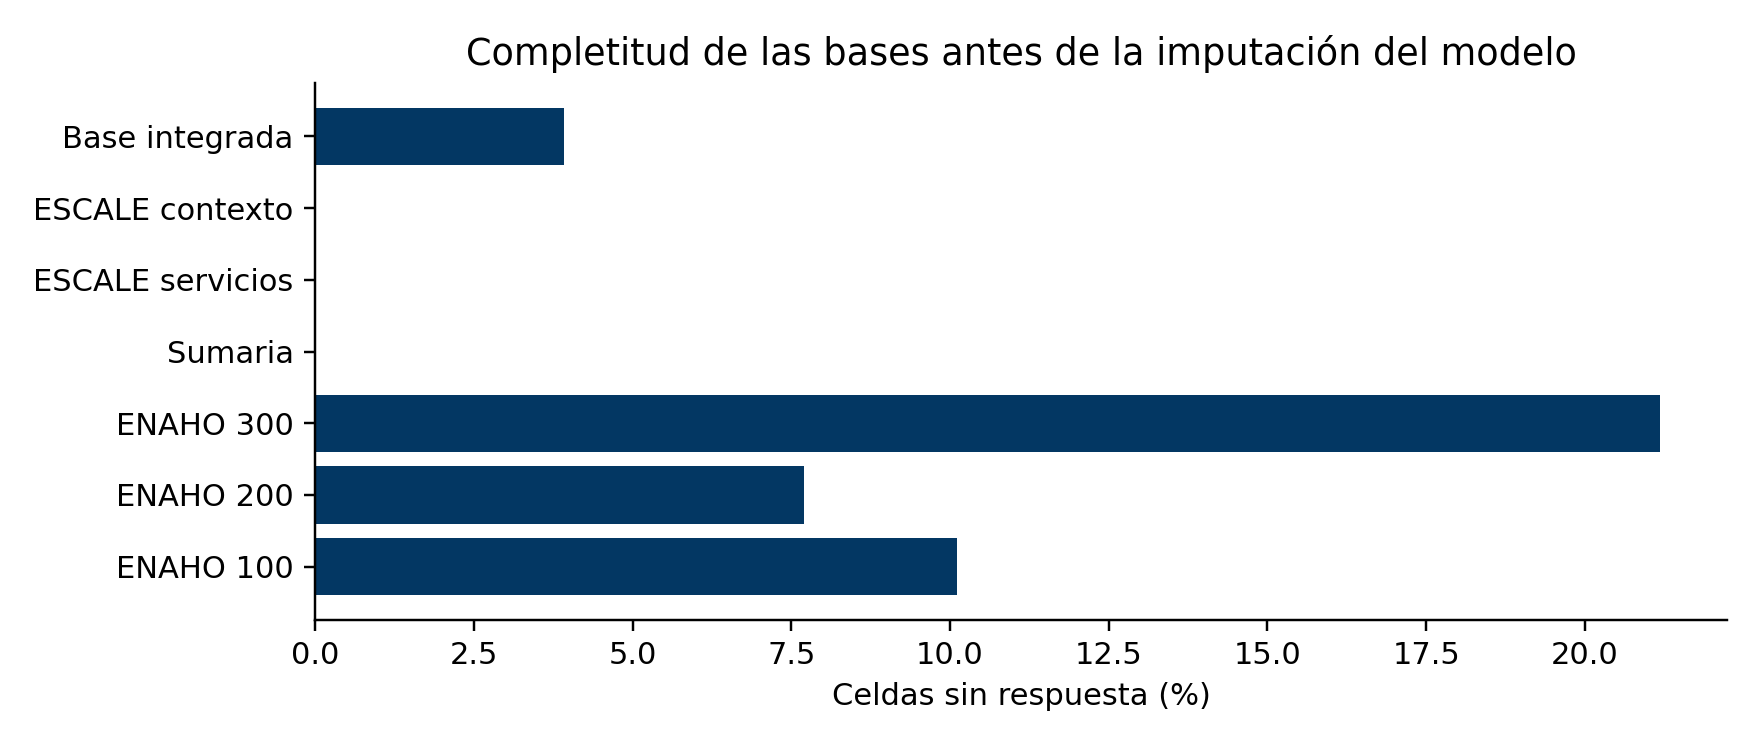

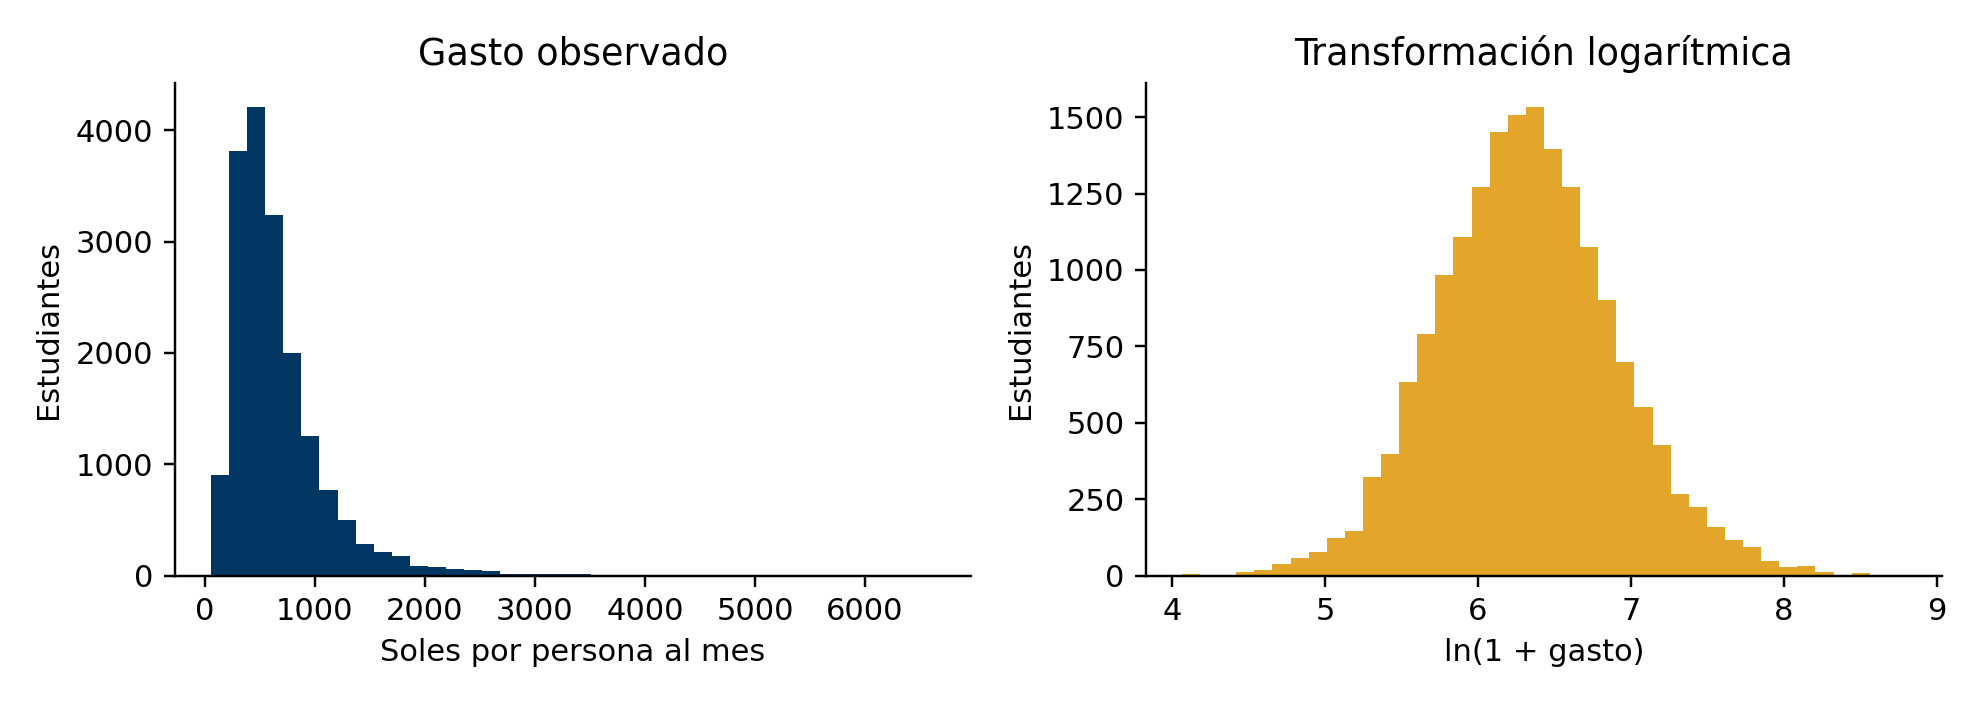

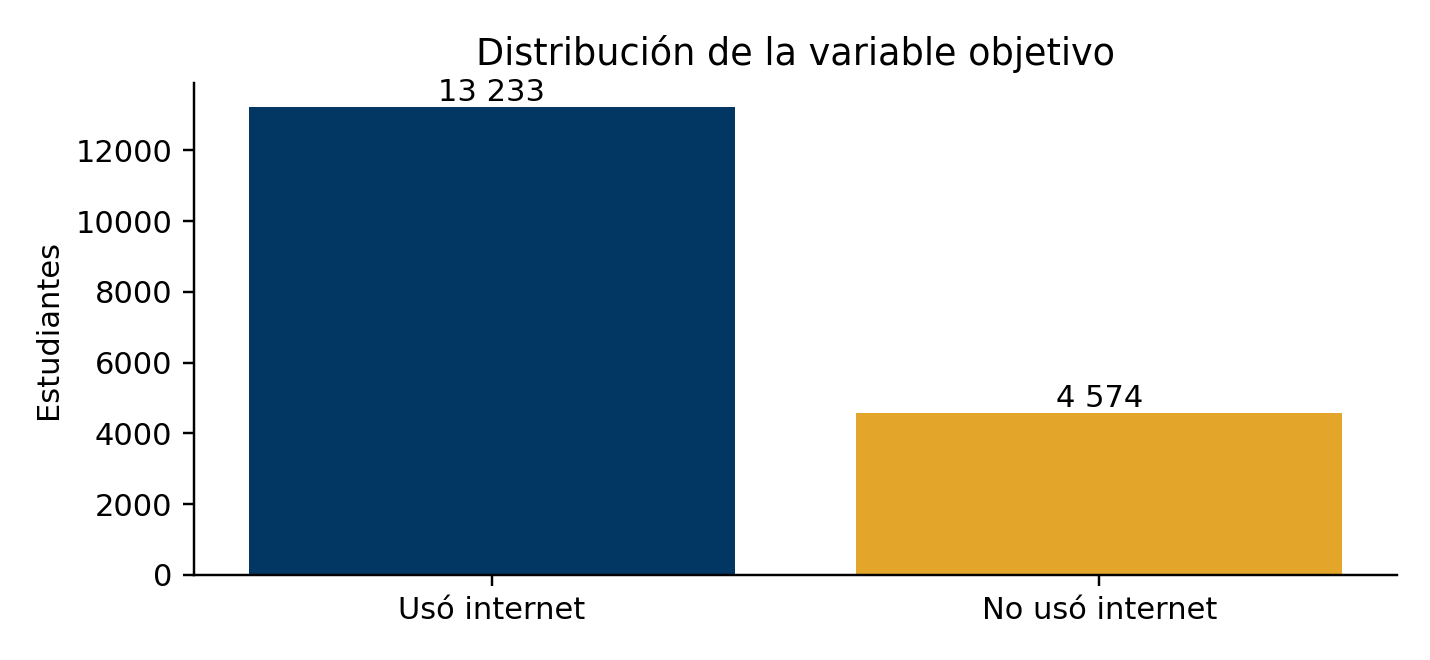

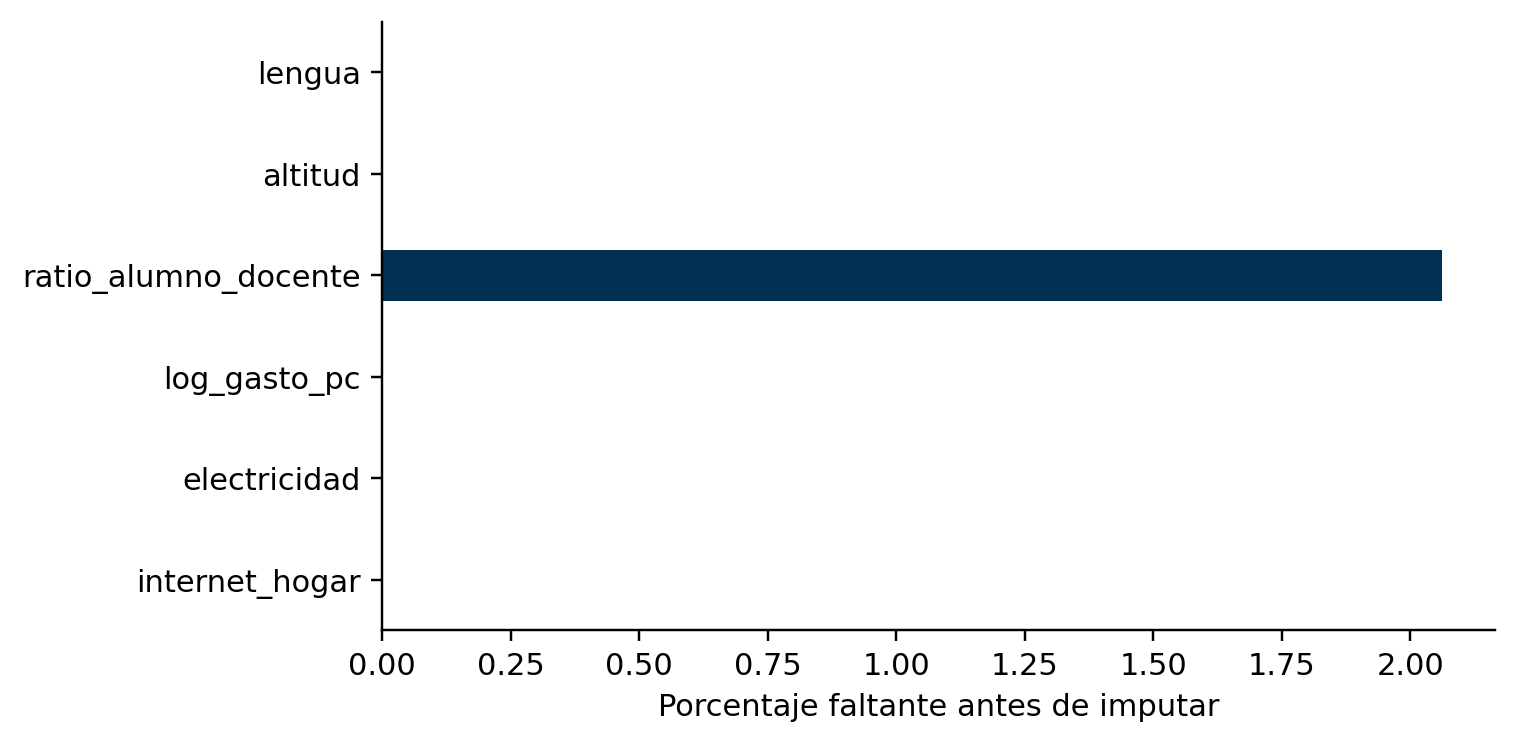

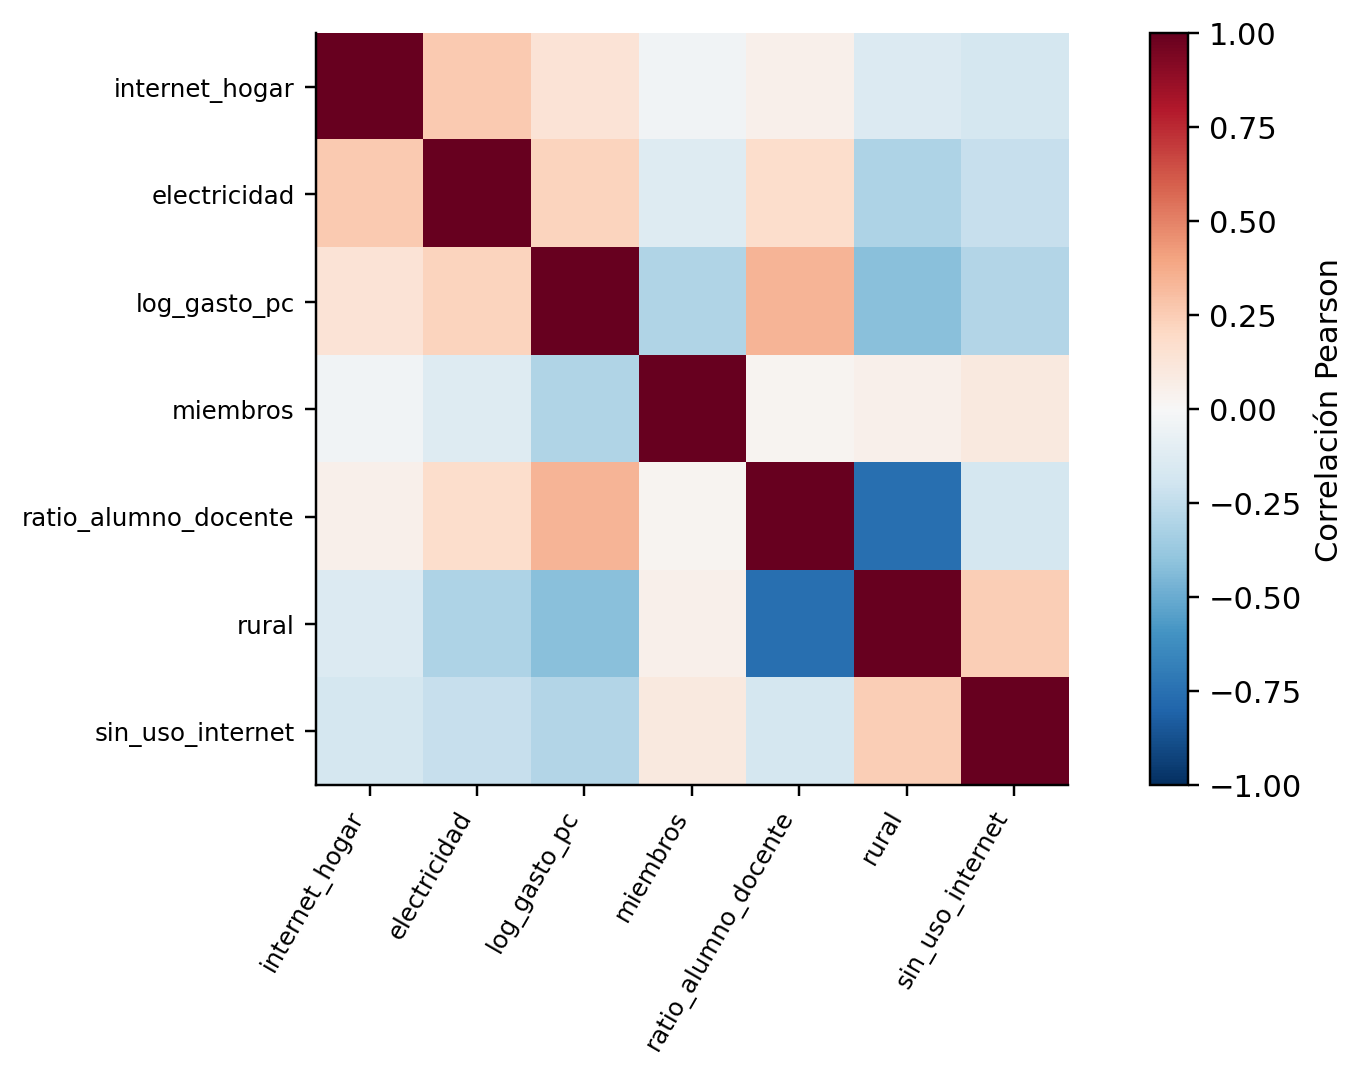

In [19]:
for archivo in ['eda_frecuencias_por_fuente','eda_distribucion_objetivo','eda_inventario_material_proporcionado']:
 print(archivo);display(pd.read_csv(TAB/f'{archivo}.csv'))
for figura in ['13_eda_completitud_fuentes.png','14_eda_gasto_antes_despues.png','15_eda_clases_objetivo.png','03_faltantes.png','04_correlaciones.png']:
 display(Image(filename=str(FIG/figura),width=850))

## Conclusión y límites
Este único notebook contiene todo el código principal y complementario utilizado en la entrega. Los resultados son transversales y no causales. La separación por conglomerado permite repetir distritos. Las estadísticas ponderadas no incluyen incertidumbre completa del diseño complejo. La regresión se omite por no disponer de un objetivo continuo educativo validado.

Para GitHub se utiliza este mismo `.ipynb`, junto con README, requirements y .gitignore. La carpeta de microdatos está excluida por .gitignore.